# Лабораторная работа №2: математический анализ и матричное исчисление

Выполнены все 25 заданий исходного шаблона: аналитические решения,
численные проверки и интерпретация результатов.
Все данные и две иллюстрации из пособия встроены в ноутбук.
Для выполнения нужны NumPy, matplotlib и обычное окружение Jupyter.
Пособие и постановка находятся рядом: `linear-algebra.pdf` и
`calculus-matrix-calculus-lab.pdf`.


## Назначение работы

Эта лабораторная работа учит читать сложные формулы как точные инструкции над числами, векторами, матрицами и тензорами. Мы начнём с сумм и индексов, перейдём к производной обычной функции, затем последовательно построим градиент, производную по направлению, полную производную, якобиан, произведения с якобианом, гессиан и матричные градиенты. В конце все операторы соединятся в одной составной параметрической функции, для которой будут вручную выведены производные, выполнена численная проверка и проведена оптимизация.

Работа образует одну непрерывную канву. Каждый следующий объект отвечает на ограничение предыдущего: одной производной недостаточно для функции многих переменных; одного градиента недостаточно для векторного выхода; полный якобиан не всегда следует строить явно; первая производная показывает направление изменения, а гессиан — изменение самого градиента и локальную кривизну.

Единственный источник теории, формул и соглашений об обозначениях — пособие [«Линейная алгебра»](linear-algebra.pdf). Из [«Высшей математики. Практикума»](02-Высшая-математика-практикум.pdf) перенесены только несколько начальных условий для ручного решения. Остальные аналитические и вычислительные задания специально составлены для этой работы.


## Как выполнять работу

Этапы помечены способом работы:

- **[Бумага]** — вывести результат аналитически без NumPy;
- **[Markdown]** — оформить рассуждение и формулы в Markdown-ячейке;
- **[Python]** — проверить вывод или исследовать численное поведение;
- **[Интерпретация]** — объяснить тип, размерность и практический смысл результата.

Сначала выполняйте пункт **[Бумага]**, затем переносите решение в ноутбук и только после этого запускайте проверочный код. Численное совпадение не заменяет вывода: программа проверяет формулу в выбранной точке, но не доказывает её для всех допустимых аргументов.

Для каждой сложной формулы придерживайтесь четырёх вопросов:

1. Каков тип входа: скаляр, вектор, матрица или тензор?
2. Какие индексы свободны, а по каким выполняется суммирование?
3. Какова размерность результата?
4. Можно ли вычислить нужное произведение, не формируя большую производную целиком?


### Единая траектория

1. Сумма по индексам превращается в матричное или тензорное произведение.
2. Предел отношения приращений определяет локальную скорость изменения.
3. Частные производные собираются в градиент.
4. Градиент задаёт изменение в выбранном направлении.
5. Производные векторной функции собираются в якобиан.
6. Цепное правило превращается в произведение якобианов или векторно-якобианное произведение.
7. Вторые частные производные образуют гессиан и описывают кривизну.
8. Индексные выводы сворачиваются в компактные матричные градиенты.
9. Градиенты составной функции проверяются конечными разностями.
10. Проверенные градиенты используются для уменьшения целевой функции.


## Соглашения и общий пакет данных

Градиент скалярной функции $f:\mathbb R^n\to\mathbb R$ считаем вектором-столбцом. Для отображения $\mathbf f:\mathbb R^n\to\mathbb R^m$ используем якобиан, строки которого соответствуют компонентам выхода:

$$
\mathbf J_{\mathbf f}(\mathbf x)
=\frac{\partial\mathbf f}{\partial\mathbf x^{\mathsf T}}
\in\mathbb R^{m\times n}.
$$

Сквозной вычислительный пример использует пакет из $N=4$ наблюдений, $D=3$ входных координат и $K=2$ выходных координат:

$$
\mathbf X=
\begin{pmatrix}
1&0&-1\\
0&1&1\\
1&1&0\\
-1&2&1
\end{pmatrix}\in\mathbb R^{4\times3},
\qquad
\mathbf Y=
\begin{pmatrix}
0.2&0.8\\
0.7&0.1\\
0.6&0.4\\
0.1&0.9
\end{pmatrix}\in\mathbb R^{4\times2}.
$$

Начальные параметры:

$$
\mathbf W_0=
\begin{pmatrix}
0.2&-0.3\\
0.4&0.1\\
-0.5&0.2
\end{pmatrix}\in\mathbb R^{3\times2},
\qquad
\mathbf b_0=
\begin{pmatrix}0.1\\-0.2\end{pmatrix},
\qquad \lambda=0.05.
$$

В конце работы вычисляется композиция

$$
\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T},
\qquad
\mathbf H=\sigma(\mathbf Z),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}},
$$

и скалярная целевая функция

$$
\mathcal L(\mathbf W,\mathbf b)
=\frac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2
+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2.
$$

Пока не дифференцируйте эту запись: к ней будем возвращаться после освоения каждого необходимого оператора.


In [1]:
"""Аналитические и численные проверки по математическому анализу."""

import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

%matplotlib inline

np.set_printoptions(precision=9, suppress=True)
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
verification_errors = {}

X_data = np.array(
    [
        [1, 0, -1],
        [0, 1, 1],
        [1, 1, 0],
        [-1, 2, 1],
    ],
    dtype=float,
)
Y_data = np.array(
    [
        [0.2, 0.8],
        [0.7, 0.1],
        [0.6, 0.4],
        [0.1, 0.9],
    ],
    dtype=float,
)
W_initial = np.array(
    [
        [0.2, -0.3],
        [0.4, 0.1],
        [-0.5, 0.2],
    ],
    dtype=float,
)
b_initial = np.array([0.1, -0.2], dtype=float)
regularization = 0.05


def sigmoid(z):
    """Вычислить поэлементную сигмоиду с ограничением аргумента exp."""
    z_safe = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_safe))


def show_table(headers, rows):
    """Показать небольшую таблицу как Markdown в выводе ячейки."""
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


def save_figure(figure, filename):
    """Сохранить график и показать его в ноутбуке."""
    figure.savefig(RESULTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(figure)


print("X:", X_data.shape, "Y:", Y_data.shape)
print("W:", W_initial.shape, "b:", b_initial.shape)
print("lambda =", regularization)
display(
    Markdown(
        "В формулах векторы — столбцы; в NumPy вектор обычно хранится с формой `(n,)`. "
        "Строки и столбцы при необходимости создаются через `reshape`. "
        "Защитное ограничение сигмоиды не срабатывает в проверяемых точках; "
        "это дополнительно проверяется при оптимизации."
    )
)

X: (4, 3) Y: (4, 2)
W: (3, 2) b: (2,)
lambda = 0.05


В формулах векторы — столбцы; в NumPy вектор обычно хранится с формой `(n,)`. Строки и столбцы при необходимости создаются через `reshape`. Защитное ограничение сигмоиды не срабатывает в проверяемых точках; это дополнительно проверяется при оптимизации.

## 1. Суммы, индексы и матричная запись


### Короткая теория

Если $\mathbf A\in\mathbb R^{m\times n}$ и $\mathbf B\in\mathbb R^{n\times p}$, то

$$
\mathbf C=\mathbf A\mathbf B\in\mathbb R^{m\times p},
\qquad
C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}.
$$

Индексы $i$ и $j$ свободны: они остаются у результата. Индекс $k$ суммируемый, или фиктивный: он пробегает допустимые значения и исчезает после суммирования. В нотации Эйнштейна знак суммы можно опустить, если правило суммирования однозначно. См. [матричное произведение, с. 15–18](linear-algebra.pdf#page=15) и [суммирование Эйнштейна, с. 20](linear-algebra.pdf#page=20).

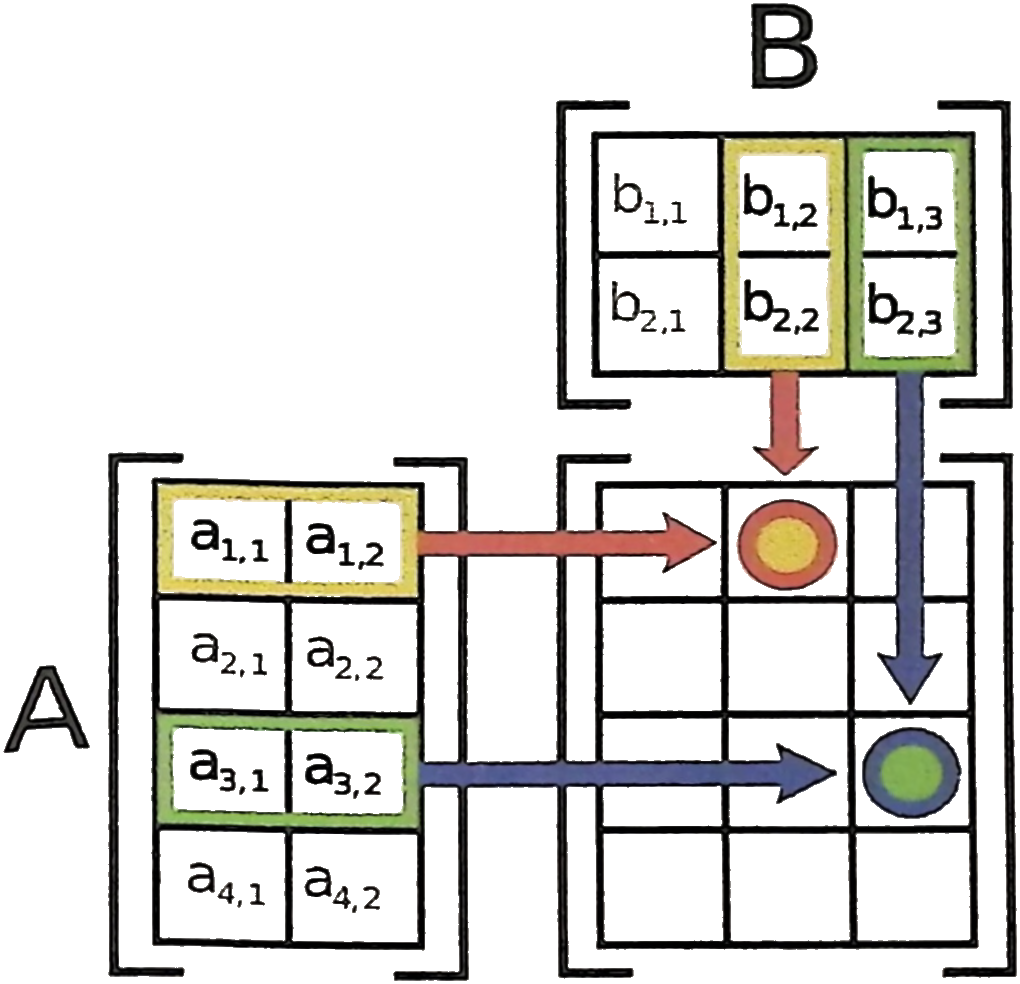

*Каждый элемент произведения получается свёрткой строки первой матрицы со столбцом второй.*


### Задание 1.1. От суммы к матрице

Даны

$$
\mathbf A=
\begin{pmatrix}1&2&-1\\0&3&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&1\\1&-1\\0&2\end{pmatrix}.
$$

- **[Бумага]** Укажите размеры $\mathbf A$, $\mathbf B$ и $\mathbf C=\mathbf A\mathbf B$. Распишите каждый $C_{ij}$ отдельной суммой.
- **[Markdown]** Подпишите свободные и суммируемый индексы в $C_{ij}=\sum_kA_{ik}B_{kj}$.
- **[Python]** Сравните ручной результат с `A @ B` и с тройным циклом по $i,j,k$.
- **[Интерпретация]** Объясните, почему индекс $k$ отсутствует в обозначении $C_{ij}$ и почему поменять местами $j$ и $k$ нельзя.


#### Решение 1.1

Матрицы имеют размеры $A\in\mathbb R^{2\times3}$ и
$B\in\mathbb R^{3\times2}$, поэтому $C\in\mathbb R^{2\times2}$.
Каждая строка $A$ сворачивается с каждым столбцом $B$:

$$\begin{aligned}
C_{11}&=1\cdot2+2\cdot1+(-1)\cdot0=4,\\
C_{12}&=1\cdot1+2\cdot(-1)+(-1)\cdot2=-3,\\
C_{21}&=0\cdot2+3\cdot1+1\cdot0=3,\\
C_{22}&=0\cdot1+3\cdot(-1)+1\cdot2=-1.
\end{aligned}$$

$$C=\begin{pmatrix}4&-3\\3&-1\end{pmatrix}.$$

В $C_{ij}=\sum_{k=1}^{3}A_{ik}B_{kj}$ индексы $i,j$ свободны,
$k$ суммируемый. После суммирования зависимость от конкретного $k$
исчезает. Просто поменять $j$ и $k$ нельзя: у них разные роли и диапазоны
($j=1,2$, $k=1,2,3$). При этом последовательное переименование фиктивного
индекса, например $k\to\ell$ во всех множителях, допустимо.


In [2]:
A = np.array([[1, 2, -1], [0, 3, 1]], dtype=float)
B = np.array([[2, 1], [1, -1], [0, 2]], dtype=float)
C_manual = np.array([[4, -3], [3, -1]], dtype=float)
C_matmul = A @ B
C_loops = np.zeros((A.shape[0], B.shape[1]))
for i in range(A.shape[0]):
    for j in range(B.shape[1]):
        for k in range(A.shape[1]):
            C_loops[i, j] += A[i, k] * B[k, j]
print("Вручную:\n", C_manual)
print("Через @:\n", C_matmul)
print("Через циклы:\n", C_loops)
np.testing.assert_array_equal(C_manual, C_matmul)
np.testing.assert_array_equal(C_manual, C_loops)

Вручную:
 [[ 4. -3.]
 [ 3. -1.]]
Через @:
 [[ 4. -3.]
 [ 3. -1.]]
Через циклы:
 [[ 4. -3.]
 [ 3. -1.]]


### Задание 1.2. Три индекса и две свёртки

Рассмотрим тензор $S_{ntk}$ и матрицы $W_{kd}$, $V_{dc}$:

$$
S=
\left[
\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix},
\begin{pmatrix}0&1&0\\0&0&1\end{pmatrix}
\right],
$$

$$
\mathbf W=
\begin{pmatrix}1&0\\0&2\\1&-1\end{pmatrix},
\qquad
\mathbf V=
\begin{pmatrix}1&-1\\2&1\end{pmatrix}.
$$

Определим

$$
L_{nc}=\sum_{t=1}^{2}\sum_{k=1}^{3}\sum_{d=1}^{2}
S_{ntk}W_{kd}V_{dc}.
$$

- **[Бумага]** Укажите размер каждого объекта и результата. Для $L_{11}$ выпишите все слагаемые до удаления нулей.
- **[Markdown]** Объясните, почему $n,c$ свободны, а $t,k,d$ суммируются. Запишите то же выражение в нотации Эйнштейна.
- **[Интерпретация]** Опишите вычисление как последовательность двух более простых преобразований с промежуточной матрицей $E_{nd}$.


#### Решение 1.2

$S\in\mathbb R^{2\times2\times3}$, $W\in\mathbb R^{3\times2}$,
$V\in\mathbb R^{2\times2}$, $L\in\mathbb R^{2\times2}$.
Для $L_{11}$ до удаления нулевых слагаемых получаем все $2\cdot3\cdot2=12$ произведений:

$$\begin{aligned}
L_{11}={}&1\cdot1\cdot1+1\cdot0\cdot2
+0\cdot0\cdot1+0\cdot2\cdot2
+0\cdot1\cdot1+0\cdot(-1)\cdot2\\
&+0\cdot1\cdot1+0\cdot0\cdot2
+1\cdot0\cdot1+1\cdot2\cdot2
+0\cdot1\cdot1+0\cdot(-1)\cdot2=5.
\end{aligned}$$

Свободные индексы $n,c$ выбирают элемент выхода; $t,k,d$ суммируются.
В строгой нотации Эйнштейна введём $q_t=1$ и запишем
$L_{nc}=S_{ntk}W_{kd}V_{dc}q_t$: теперь каждый суммируемый индекс
встречается дважды. Без $q_t$ индекс $t$ встречался бы один раз,
и его суммирование пришлось бы оговаривать отдельно.

Сначала суммируем по $t$ и сворачиваем $k$:
$$E_{nd}=\sum_{t,k}S_{ntk}W_{kd},\qquad
E=\begin{pmatrix}1&2\\1&1\end{pmatrix}\in\mathbb R^{2\times2}.$$
Например, $E_{1,:}=W_{1,:}+W_{2,:}=(1,2)$,
$E_{2,:}=W_{2,:}+W_{3,:}=(1,1)$.
Затем
$$L=EV=\begin{pmatrix}1+4&-1+2\\1+2&-1+1\end{pmatrix}
=\begin{pmatrix}5&1\\3&0\end{pmatrix}.$$


In [3]:
S_tensor = np.array(
    [
        [[1, 0, 0], [0, 1, 0]],
        [[0, 1, 0], [0, 0, 1]],
    ],
    dtype=float,
)
W_tensor = np.array([[1, 0], [0, 2], [1, -1]], dtype=float)
V_tensor = np.array([[1, -1], [2, 1]], dtype=float)
expected_E_shape = (S_tensor.shape[0], W_tensor.shape[1])
expected_L_shape = (S_tensor.shape[0], V_tensor.shape[1])
print("S:", S_tensor.shape, "W:", W_tensor.shape, "V:", V_tensor.shape)
print("Ожидаем E:", expected_E_shape, "L:", expected_L_shape)
assert S_tensor.shape[2] == W_tensor.shape[0]
assert W_tensor.shape[1] == V_tensor.shape[0]

S: (2, 2, 3) W: (3, 2) V: (2, 2)
Ожидаем E: (2, 2) L: (2, 2)


### Задание 1.3. Циклы, матрицы и `einsum`

- **[Python]** Вычислите $L_{nc}$ четырьмя способами: вложенными циклами, через промежуточную матрицу $E$, одним `np.einsum` и двумя последовательными `np.einsum`.
- **[Markdown]** Запишите строки индексов для `einsum` и сопоставьте их математическим индексам.
- **[Интерпретация]** Объясните, почему совпадение четырёх реализаций является хорошей проверкой индексов, но не заменяет проверки размерностей до запуска.


#### Решение 1.3

Одна свёртка записывается как `ntk,kd,dc->nc`.
В `einsum` индексы слева, не указанные справа, суммируются, в том числе
индекс `t`, который присутствует лишь в одном входе.
Это более общее правило, чем строгое соглашение Эйнштейна из задания 1.2.

Два шага: `ntk,kd->nd`, затем `nd,dc->nc`.
Через матрицы: $E=(\sum_tS_{:,t,:})W$, $L=EV$.
Все четыре реализации должны дать $L=\begin{pmatrix}5&1\\3&0\end{pmatrix}$.
Совпадение помогает найти ошибки индексов, однако проверка форм до вычисления
необходима: при одинаковых размерах неверная перестановка может остаться незаметной.


In [4]:
L_loops = np.zeros(expected_L_shape)
for n in range(S_tensor.shape[0]):
    for c in range(V_tensor.shape[1]):
        for t in range(S_tensor.shape[1]):
            for k in range(S_tensor.shape[2]):
                for d in range(W_tensor.shape[1]):
                    L_loops[n, c] += S_tensor[n, t, k] * W_tensor[k, d] * V_tensor[d, c]
E_matrix = S_tensor.sum(axis=1) @ W_tensor
L_matrix = E_matrix @ V_tensor
L_einsum_once = np.einsum("ntk,kd,dc->nc", S_tensor, W_tensor, V_tensor)
E_einsum = np.einsum("ntk,kd->nd", S_tensor, W_tensor)
L_einsum_twice = np.einsum("nd,dc->nc", E_einsum, V_tensor)
assert E_matrix.shape == expected_E_shape
for name, result in [
    ("Циклы", L_loops),
    ("Матрицы", L_matrix),
    ("Один einsum", L_einsum_once),
    ("Два einsum", L_einsum_twice),
]:
    print(name, "\n", result)
    assert result.shape == expected_L_shape
    np.testing.assert_allclose(result, [[5, 1], [3, 0]])

Циклы 
 [[5. 1.]
 [3. 0.]]
Матрицы 
 [[5. 1.]
 [3. 0.]]
Один einsum 
 [[5. 1.]
 [3. 0.]]
Два einsum 
 [[5. 1.]
 [3. 0.]]


## 2. Функции одной переменной


### Короткая теория

Производная функции $f:\mathbb R\to\mathbb R$ в точке $x$ определяется пределом

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

Для малого $h$ функция локально заменяется касательной:

$$
f(x+h)\approx f(x)+f'(x)h.
$$

Прямую, центральную и обратную конечные разности, а также причину потери точности при слишком малом $h$ см. в [теории, с. 39–40](linear-algebra.pdf#page=39). Правила для степенной, экспоненциальной, логарифмической и сложной функций приведены на [с. 42](linear-algebra.pdf#page=42).


### Задание 2.1. Производная как предел и как численный оператор

Для $f(x)=e^x$ и $x_0=1$ рассмотрите

$$
D_+(h)=\frac{f(x_0+h)-f(x_0)}{h},
\quad
D_0(h)=\frac{f(x_0+h/2)-f(x_0-h/2)}{h},
\quad
D_-(h)=\frac{f(x_0)-f(x_0-h)}{h}.
$$

- **[Бумага]** Найдите точную производную и уравнение касательной в $x_0$.
- **[Markdown]** Объясните, почему все три выражения стремятся к одному числу, но при конечном $h$ имеют разные ошибки.
- **[Python]** Для $h=10^{-1},\ldots,10^{-16}$ вычислите абсолютные ошибки и постройте логарифмический график. Отдельно покажите функцию и касательную около $x_0$.
- **[Интерпретация]** Найдите область лучших $h$ и объясните рост ошибки при чрезмерно малом шаге вычитанием близких чисел.


#### Решение 2.1

$$f'(x)=\lim_{h\to0}e^x\frac{e^h-1}{h}=e^x,\qquad f'(1)=e.$$
Касательная: $y=f(1)+f'(1)(x-1)=e+e(x-1)=ex$.
Вход и выход — скаляры; производная также скаляр.

Разложения по $h$ объясняют различие ошибок:
$$D_+(h)=e\left(1+\frac h2+O(h^2)\right),\qquad
D_-(h)=e\left(1-\frac h2+O(h^2)\right),$$
$$D_0(h)=e\left(1+\frac{h^2}{24}+O(h^4)\right).$$
Прямая и обратная разности имеют ошибку порядка $h$, центральная — $h^2$.
Их предел одинаков, потому что функция дифференцируема.
При слишком малом $h$ числа $f(1+h)$ и $f(1)$ почти равны,
а округление при вычитании усиливается делением на $h$.
Лучший шаг определяется балансом ошибки приближения и округления;
найденные на заданной сетке значения выводятся ниже и зависят от вычислительной среды.

**Результат эксперимента:** на заданной сетке минимальная ошибка прямой и обратной разностей получена при $h=10^{-8}$, центральной — при $h=10^{-5}$. Для центральной схемы подходящая область шагов здесь существенно шире, чем предельно малые $10^{-15}$–$10^{-16}$.


| h | Ошибка прямой | Ошибка центральной | Ошибка обратной |
| --- | --- | --- | --- |
| 1e-01 | 1.406e-01 | 1.133e-03 | 1.315e-01 |
| 1e-02 | 1.364e-02 | 1.133e-05 | 1.355e-02 |
| 1e-03 | 1.360e-03 | 1.133e-07 | 1.359e-03 |
| 1e-04 | 1.359e-04 | 1.133e-09 | 1.359e-04 |
| 1e-05 | 1.359e-05 | 5.859e-11 | 1.359e-05 |
| 1e-06 | 1.359e-06 | 5.859e-11 | 1.359e-06 |
| 1e-07 | 1.399e-07 | 2.162e-09 | 1.398e-07 |
| 1e-08 | 6.603e-09 | 6.603e-09 | 6.603e-09 |
| 1e-09 | 2.154e-07 | 2.154e-07 | 2.286e-07 |
| 1e-10 | 1.548e-06 | 1.548e-06 | 2.893e-06 |
| 1e-11 | 3.263e-05 | 1.177e-05 | 1.177e-05 |
| 1e-12 | 4.323e-04 | 1.177e-05 | 1.177e-05 |
| 1e-13 | 4.559e-04 | 4.897e-03 | 4.559e-04 |
| 1e-14 | 9.338e-03 | 3.507e-02 | 9.338e-03 |
| 1e-15 | 3.903e-01 | 5.375e-02 | 5.375e-02 |
| 1e-16 | 2.718e+00 | 2.718e+00 | 2.718e+00 |

| Разность | Лучший h на сетке | Минимальная ошибка |
| --- | --- | --- |
| Прямая | 1e-08 | 6.603e-09 |
| Центральная | 1e-05 | 5.859e-11 |
| Обратная | 1e-08 | 6.603e-09 |

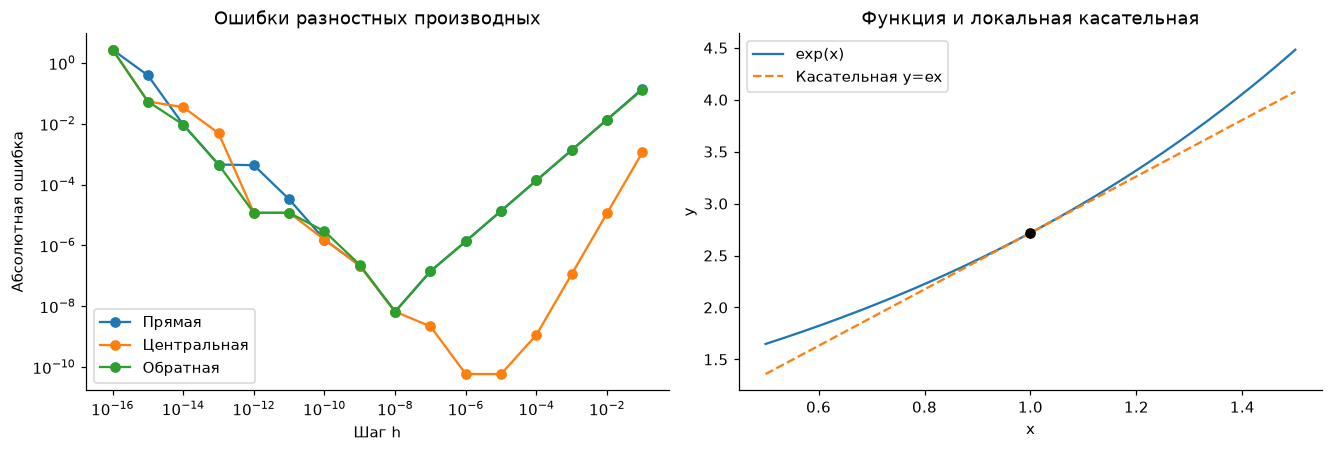

In [5]:
x0 = 1.0
h_values = np.logspace(-1, -16, 16)
exact_derivative = np.exp(x0)
difference_values = {
    "Прямая": (np.exp(x0 + h_values) - np.exp(x0)) / h_values,
    "Центральная": (np.exp(x0 + h_values / 2) - np.exp(x0 - h_values / 2)) / h_values,
    "Обратная": (np.exp(x0) - np.exp(x0 - h_values)) / h_values,
}
difference_errors = {
    name: np.abs(values - exact_derivative)
    for name, values in difference_values.items()
}
show_table(
    ["h", "Ошибка прямой", "Ошибка центральной", "Ошибка обратной"],
    [
        [f"{step:.0e}"]
        + [f"{difference_errors[name][i]:.3e}" for name in difference_values]
        for i, step in enumerate(h_values)
    ],
)
show_table(
    ["Разность", "Лучший h на сетке", "Минимальная ошибка"],
    [
        [name, f"{h_values[np.argmin(errors)]:.0e}", f"{errors.min():.3e}"]
        for name, errors in difference_errors.items()
    ],
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for name, errors in difference_errors.items():
    axes[0].loglog(h_values, np.where(errors > 0, errors, np.nan), "o-", label=name)
axes[0].set(
    title="Ошибки разностных производных", xlabel="Шаг h", ylabel="Абсолютная ошибка"
)
axes[0].legend()
x_plot = np.linspace(0.5, 1.5, 250)
axes[1].plot(x_plot, np.exp(x_plot), label="exp(x)")
axes[1].plot(
    x_plot,
    np.exp(x0) + exact_derivative * (x_plot - x0),
    "--",
    label="Касательная y=ex",
)
axes[1].scatter([x0], [np.exp(x0)], color="black", zorder=3)
axes[1].set(title="Функция и локальная касательная", xlabel="x", ylabel="y")
axes[1].legend()
save_figure(fig, "01_finite_differences.png")

### Задание 2.2. Правила дифференцирования

Источник условий: [практикум, с. 71, задачи 1, 2, 4 и 6](02-Высшая-математика-практикум.pdf#page=71).

Найдите производные и вычислите их при $x=1$:

$$
\begin{aligned}
&1)\quad y=2x^3-5x^2+7x+4;\\
&2)\quad y=x^2e^x;\\
&3)\quad y=(2x^2+5)^2;\\
&4)\quad y=\ln(2x^3+3x^2).
\end{aligned}
$$

- **[Бумага]** Для каждой функции назовите используемые правила и сохраните производную как функцию от $x$ до подстановки.
- **[Markdown]** Особо выделите внешний и внутренний аргументы в пунктах 3 и 4.
- **[Python]** Проверьте значения центральной разностью при $h=10^{-5}$.
- **[Интерпретация]** Сравните знаки и модули производных как локальные скорости изменения четырёх разных функций.


#### Решение 2.2

1. По линейности и правилу степени:
   $y'=6x^2-10x+7$, поэтому $y'(1)=6-10+7=3$.
2. По правилу произведения:
   $y'=2xe^x+x^2e^x=e^x(x^2+2x)$, поэтому $y'(1)=3e\approx8.154845$.
3. Внешняя функция $u^2$, внутренняя $u=2x^2+5$:
   $y'=2u\cdot u'=2(2x^2+5)\cdot4x=8x(2x^2+5)$,
   $y'(1)=8\cdot7=56$.
4. Внешняя функция $\ln u$, внутренняя $u=2x^3+3x^2$:
   $$y'=\frac{u'}u=\frac{6x^2+6x}{2x^3+3x^2},\qquad y'(1)=\frac{12}{5}=2.4.$$

Для логарифма требуется $x^2(2x+3)>0$, то есть
$x\in(-3/2,0)\cup(0,+\infty)$; точка $x=1$ допустима.
Все четыре производные в этой точке положительны: функции локально возрастают.
Наибольшая скорость у третьей функции — 56, наименьшая у четвёртой — 2.4.
Численная разность проверяет значения в одной точке, а правила выше дают формулы для всей области определения.


In [6]:
x0 = 1.0
h = 1e-5
functions = [
    lambda x: 2 * x**3 - 5 * x**2 + 7 * x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2 * x**2 + 5) ** 2,
    lambda x: np.log(2 * x**3 + 3 * x**2),
]
derivatives = [
    lambda x: 6 * x**2 - 10 * x + 7,
    lambda x: np.exp(x) * (x**2 + 2 * x),
    lambda x: 8 * x * (2 * x**2 + 5),
    lambda x: (6 * x**2 + 6 * x) / (2 * x**3 + 3 * x**2),
]
derivative_rows = []
for index, (function, derivative) in enumerate(
    zip(functions, derivatives, strict=True), 1
):
    exact = derivative(x0)
    numerical = (function(x0 + h) - function(x0 - h)) / (2 * h)
    error = abs(exact - numerical)
    derivative_rows.append([index, f"{exact:.9f}", f"{numerical:.9f}", f"{error:.3e}"])
    np.testing.assert_allclose(exact, numerical, rtol=1e-8, atol=1e-8)
show_table(
    ["Функция", "Аналитически", "Центральная разность", "Ошибка"], derivative_rows
)

| Функция | Аналитически | Центральная разность | Ошибка |
| --- | --- | --- | --- |
| 1 | 3.000000000 | 3.000000000 | 2.417e-10 |
| 2 | 8.154845485 | 8.154845486 | 5.976e-10 |
| 3 | 56.000000000 | 56.000000002 | 2.143e-09 |
| 4 | 2.400000000 | 2.400000000 | 5.791e-11 |

### Задание 2.3. Дифференциал и граница дифференцируемости

Источник первого условия: [практикум, с. 72, задача 2](02-Высшая-математика-практикум.pdf#page=72).

Для $y=\ln(1+x^2)$ найдите дифференциал $dy$ и используйте его для приближённого вычисления изменения при переходе от $x=1$ к $x=1.02$.

Затем исследуйте $r(x)=\max(0,x)$ в точке $x=0$.

- **[Бумага]** Найдите $dy=y'(x)dx$, левую и правую производные $r$ в нуле.
- **[Markdown]** Объясните, почему совпадение односторонних пределов необходимо для обычной производной.
- **[Python]** Сравните линейное приближение логарифмической функции с точным изменением; постройте $r(x)$ и её односторонние секущие. Вычислите центральную разность в нуле.
- **[Интерпретация]** Объясните, почему конечная центральная разность может вернуть число даже там, где производная не существует.


#### Решение 2.3

Для $y=\ln(1+x^2)$ цепное правило даёт
$$dy=y'(x)dx=\frac{2x}{1+x^2}dx.$$
При $x=1$, $dx=0.02$ получаем $dy=0.02$,
а $y(1.02)\approx\ln2+0.02$.
Точное изменение равно
$$\Delta y=\ln(2.0404)-\ln2=\ln(1.0202)\approx0.019998687.$$
Линейное приближение завышает изменение примерно на $1.31\cdot10^{-6}$.

У $r(x)=\max(0,x)$ левая производная в нуле равна 0, правая — 1:
$$\lim_{h\to0^-}\frac{r(h)-r(0)}h=0,\qquad
\lim_{h\to0^+}\frac{r(h)-r(0)}h=1.$$
Поэтому обычной производной в нуле нет. Между тем
$$\frac{r(h)-r(-h)}{2h}=\frac12\qquad(h>0).$$
Центральная разность возвращает число даже в недифференцируемой точке;
сама по себе она не доказывает существование производной.


dy: 0.02 точное изменение: 0.019998686506689123
Ошибка приближения: 1.3134933108775726e-06
Левая, правая, центральная разности: 0.0 1.0 0.5


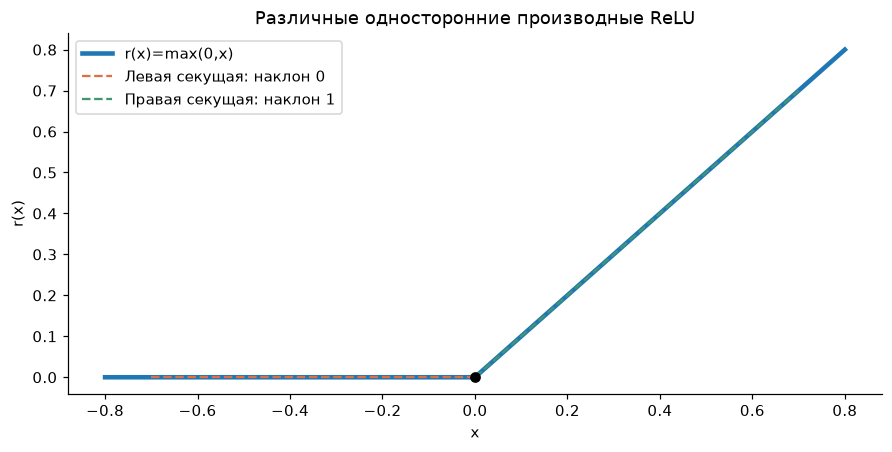

In [7]:
x0, dx = 1.0, 0.02
differential_coefficient = 2 * x0 / (1 + x0**2)
linear_log_change = differential_coefficient * dx
exact_log_change = np.log1p((x0 + dx) ** 2) - np.log1p(x0**2)
print("dy:", linear_log_change, "точное изменение:", exact_log_change)
print("Ошибка приближения:", abs(linear_log_change - exact_log_change))


def relu(x):
    """Вернуть положительную часть скаляра или массива."""
    return np.maximum(0.0, x)


h = 1e-5
left_relu = (relu(0.0) - relu(-h)) / h
right_relu = (relu(h) - relu(0.0)) / h
central_relu = (relu(h) - relu(-h)) / (2 * h)
print("Левая, правая, центральная разности:", left_relu, right_relu, central_relu)
np.testing.assert_allclose([left_relu, right_relu, central_relu], [0, 1, 0.5])
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
x_plot = np.linspace(-0.8, 0.8, 300)
ax.plot(x_plot, relu(x_plot), linewidth=3, label="r(x)=max(0,x)")
ax.plot([-0.7, 0.0], [0.0, 0.0], "--", color="#db704b", label="Левая секущая: наклон 0")
ax.plot([0.0, 0.7], [0.0, 0.7], "--", color="#42956f", label="Правая секущая: наклон 1")
ax.scatter([0], [0], color="black", zorder=4)
ax.set(title="Различные односторонние производные ReLU", xlabel="x", ylabel="r(x)")
ax.legend()
save_figure(fig, "02_relu.png")

## 3. Частные производные, градиент и дифференциал


### Короткая теория

Для $f:\mathbb R^n\to\mathbb R$ частная производная меняет только одну координату:

$$
\frac{\partial f}{\partial x_i}
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x)}{h}.
$$

Все частные производные собираются в градиент

$$
\nabla f(\mathbf x)=
\begin{pmatrix}
\partial f/\partial x_1\\ \vdots\\ \partial f/\partial x_n
\end{pmatrix}.
$$

При малом $\Delta\mathbf x$ полный дифференциал задаёт линейное приближение

$$
\Delta f\approx df=\nabla f(\mathbf x)^{\mathsf T}\Delta\mathbf x.
$$

См. [градиент и частные производные, с. 40](linear-algebra.pdf#page=40).


### Задание 3.1. Полный дифференциал многочлена

Источник условия: [практикум, с. 140, задача 1в](02-Высшая-математика-практикум.pdf#page=140).

Для

$$
z=5x^3+2x^2y^4-6x+9y
$$

найдите $\partial z/\partial x$, $\partial z/\partial y$, градиент и полный дифференциал. Вычислите градиент в точке $(1,-1)$.

- **[Бумага]** При дифференцировании по одной переменной явно обозначьте другую как постоянную.
- **[Markdown]** Запишите $dz$ сначала через частные производные, затем в раскрытом виде.
- **[Python]** Проверьте обе компоненты градиента центральными покоординатными разностями.
- **[Интерпретация]** Объясните, почему коэффициент при $dx$ равен первой компоненте градиента, а коэффициент при $dy$ — второй.


#### Решение 3.1

При дифференцировании по $x$ считаем $y$ постоянной:
$$z_x=15x^2+4xy^4-6.$$
При дифференцировании по $y$ считаем $x$ постоянной:
$$z_y=8x^2y^3+9.$$
Следовательно,
$$\nabla z=\begin{pmatrix}15x^2+4xy^4-6\\8x^2y^3+9\end{pmatrix}
\in\mathbb R^{2\times1},$$
$$dz=z_xdx+z_ydy=(15x^2+4xy^4-6)dx+(8x^2y^3+9)dy.$$
В точке $(1,-1)$:
$$z_x=15+4-6=13,\qquad z_y=-8+9=1,\qquad
\nabla z=\begin{pmatrix}13\\1\end{pmatrix},\quad dz=13dx+dy.$$
Дифференциал — скаляр, получаемый умножением строки $\nabla z^{\mathsf T}$
на столбец приращений $(dx,dy)^{\mathsf T}$.
Поэтому коэффициенты при $dx,dy$ являются соответствующими компонентами градиента.


In [8]:
def z_practice(point):
    """Вычислить многочлен из задания 3.1."""
    x, y = point
    return 5 * x**3 + 2 * x**2 * y**4 - 6 * x + 9 * y


point = np.array([1.0, -1.0])
gradient_exact = np.array([13.0, 1.0])
h = 1e-5
gradient_numerical = np.array(
    [
        (z_practice(point + h * direction) - z_practice(point - h * direction))
        / (2 * h)
        for direction in np.eye(point.size)
    ]
)
print("Значение функции:", z_practice(point))
print("Градиент аналитический:", gradient_exact)
print("Градиент численный:", gradient_numerical)
verification_errors["3.1 gradient"] = float(
    np.linalg.norm(gradient_exact - gradient_numerical)
)
print("Норма ошибки:", verification_errors["3.1 gradient"])
np.testing.assert_allclose(gradient_numerical, gradient_exact, atol=1e-7, rtol=0)

Значение функции: -8.0
Градиент аналитический: [13.  1.]
Градиент численный: [13.           0.999999999]
Норма ошибки: 8.683816026498536e-10


### Задание 3.2. Локальная плоскость вместо касательной

Пусть

$$
f(x,y)=x^2+xy+2y^2-3x+1,
\qquad \mathbf x_0=(1,-1)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla f$, $f(\mathbf x_0)$ и линейную модель $f(\mathbf x_0+\Delta\mathbf x)$.
- **[Markdown]** Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ вычислите прогноз изменения.
- **[Python]** Сравните прогноз с точным изменением. Постройте линии уровня, точку $\mathbf x_0$, градиент и выбранное приращение.
- **[Интерпретация]** Объясните геометрическое различие между касательной к графику одной переменной и касательной плоскостью для двух переменных.


#### Решение 3.2

$$\nabla f(x,y)=\begin{pmatrix}2x+y-3\\x+4y\end{pmatrix},\qquad
f(1,-1)=1-1+2-3+1=0,\qquad
\nabla f(1,-1)=\begin{pmatrix}-2\\-3\end{pmatrix}.$$
При $\Delta=(\Delta x,\Delta y)^{\mathsf T}$ линейная модель равна
$$f(\mathbf x_0+\Delta)\approx-2\Delta x-3\Delta y.$$
Касательная плоскость к графику: $z=-2(x-1)-3(y+1)$.
Для $\Delta=(0.01,-0.02)^{\mathsf T}$:
$$\Delta f_{\mathrm{lin}}=-2\cdot0.01-3\cdot(-0.02)=0.04.$$
Поскольку функция квадратичная, точное изменение включает остаток
$$\Delta x^2+\Delta x\Delta y+2\Delta y^2
=0.0001-0.0002+0.0008=0.0007.$$
Следовательно, $\Delta f=0.0407$: линейная модель занижает изменение на 0.0007.
У функции одной переменной график — кривая с касательной прямой;
у функции двух переменных график — поверхность, а локальная линейная модель — плоскость.


f(x0): 0.0 градиент: [-2. -3.]
Линейное изменение: 0.039999999999999994 точное: 0.040699999999999736
Ошибка линейного приближения: 0.0006999999999997425


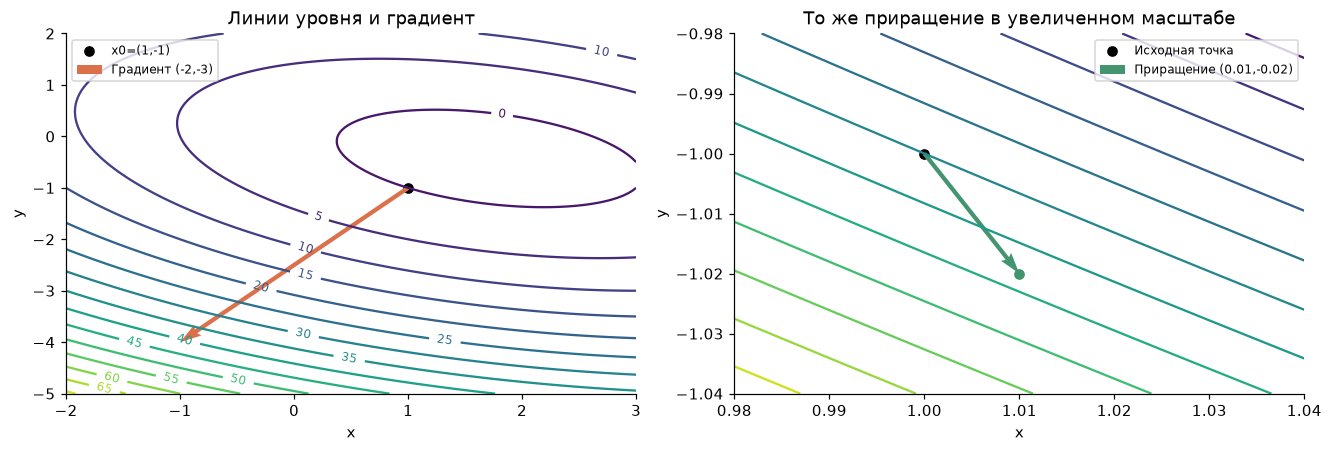

In [9]:
def f_quadratic(point):
    """Вычислить квадратичную функцию из задания 3.2."""
    x, y = point
    return x**2 + x * y + 2 * y**2 - 3 * x + 1


def gradient_quadratic(point):
    """Вычислить аналитический градиент квадратичной функции."""
    x, y = point
    return np.array([2 * x + y - 3, x + 4 * y])


x_base = np.array([1.0, -1.0])
delta = np.array([0.01, -0.02])
gradient_base = gradient_quadratic(x_base)
linear_change = gradient_base @ delta
exact_change = f_quadratic(x_base + delta) - f_quadratic(x_base)
print("f(x0):", f_quadratic(x_base), "градиент:", gradient_base)
print("Линейное изменение:", linear_change, "точное:", exact_change)
print("Ошибка линейного приближения:", abs(exact_change - linear_change))
np.testing.assert_allclose([linear_change, exact_change], [0.04, 0.0407])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
gx, gy = np.meshgrid(np.linspace(-2, 3, 150), np.linspace(-5, 2, 150))
contours = axes[0].contour(gx, gy, f_quadratic((gx, gy)), levels=14)
axes[0].clabel(contours, fontsize=8)
axes[0].scatter(*x_base, color="black", label="x0=(1,-1)")
axes[0].quiver(
    *x_base,
    *gradient_base,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="#db704b",
    label="Градиент (-2,-3)",
)
axes[0].set(title="Линии уровня и градиент", xlabel="x", ylabel="y")
axes[0].legend(fontsize=8)
gx_local, gy_local = np.meshgrid(
    np.linspace(0.98, 1.04, 100), np.linspace(-1.04, -0.98, 100)
)
axes[1].contour(gx_local, gy_local, f_quadratic((gx_local, gy_local)), levels=12)
axes[1].scatter(*x_base, color="black", label="Исходная точка")
axes[1].quiver(
    *x_base,
    *delta,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="#42956f",
    label="Приращение (0.01,-0.02)",
)
axes[1].scatter(*(x_base + delta), color="#42956f")
axes[1].set(title="То же приращение в увеличенном масштабе", xlabel="x", ylabel="y")
axes[1].legend(fontsize=8)
save_figure(fig, "03_gradient_and_increment.png")

### Задание 3.3. Численный градиент по координатам

- **[Бумага]** Запишите центральную разность для каждой компоненты $\nabla f(\mathbf x)$ через $\mathbf e_i$.
- **[Python]** Реализуйте функцию `central_gradient(f, x, h)`, не зашивая число координат. Проверьте её на функции из задания 3.2 для нескольких $h$.
- **[Markdown]** Сопоставьте аналитический и численный векторы и укажите норму ошибки.
- **[Интерпретация]** Посчитайте число обращений к $f$ для центральной разности в $n$ измерениях и объясните, почему цена растёт с размерностью.


#### Решение 3.3

Для каждой компоненты
$$[\nabla f(\mathbf x)]_i\approx
\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x-h\mathbf e_i)}{2h},
\qquad i=1,\ldots,n.$$
Результат имеет ту же форму, что и аргумент; для вектора это $n$ чисел.
Центральная разность требует $2n$ вызовов скалярной функции.
Каждый вызов может сам зависеть от размерности, поэтому общая цена
включает и стоимость вычисления $f$.

Аналитический результат в точке $(1,-1)$ — $(-2,-3)^{\mathsf T}$.
У квадратичной функции центральная разность в точной арифметике совпадает
с производной при любом ненулевом шаге: квадратичные члены сокращаются.
Поэтому здесь ошибки в таблице связаны с округлением, а при очень малом
$h$ усиливается вычитание близких значений.
Реализация ниже также поддерживает матрицы: это пригодится в разделе 7.


In [10]:
def central_gradient(function, point, h=1e-5):
    """Вычислить центральный градиент скалярной функции по всем элементам."""
    point = np.asarray(point, dtype=float)
    gradient = np.zeros_like(point)
    for index in np.ndindex(point.shape):
        plus = point.copy()
        minus = point.copy()
        plus[index] += h
        minus[index] -= h
        gradient[index] = (function(plus) - function(minus)) / (2 * h)
    return gradient


gradient_steps = [1e-1, 1e-3, 1e-5, 1e-7, 1e-9, 1e-11]
gradient_rows = []
for step in gradient_steps:
    numerical = central_gradient(f_quadratic, x_base, h=step)
    error = np.linalg.norm(numerical - gradient_base)
    gradient_rows.append([f"{step:.0e}", np.array2string(numerical), f"{error:.3e}"])
print("Аналитический градиент:", gradient_base)
show_table(["h", "Численный градиент", "Норма ошибки"], gradient_rows)
np.testing.assert_allclose(
    central_gradient(f_quadratic, x_base), gradient_base, atol=1e-8, rtol=0
)

Аналитический градиент: [-2. -3.]


| h | Численный градиент | Норма ошибки |
| --- | --- | --- |
| 1e-01 | [-2. -3.] | 6.280e-16 |
| 1e-03 | [-2. -3.] | 3.491e-13 |
| 1e-05 | [-2. -3.] | 9.453e-12 |
| 1e-07 | [-1.999999999 -3.000000002] | 2.044e-09 |
| 1e-09 | [-1.999999943 -3.000000026] | 6.233e-08 |
| 1e-11 | [-2.000000165 -3.000000248] | 2.983e-07 |

## 4. Производная по направлению и полная производная


### Короткая теория

Производная по направлению $\mathbf v$ равна

$$
D_{\mathbf v}f(\mathbf x)
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf v)-f(\mathbf x)}{h}
=\nabla f(\mathbf x)^{\mathsf T}\mathbf v.
$$

При зависимых аргументах используется полная производная:

$$
\frac{dF}{dt}
=\frac{\partial F}{\partial t}
+\frac{\partial F}{\partial x}\frac{dx}{dt}
+\frac{\partial F}{\partial y}\frac{dy}{dt}.
$$

Оба оператора приведены в [теории, с. 40](linear-algebra.pdf#page=40).


### Задание 4.1. Изменение вдоль выбранного направления

Используйте функцию и точку из задания 3.2, а также единичный вектор

$$
\mathbf v=\frac15(3,4)^{\mathsf T}.
$$

- **[Бумага]** Вычислите $D_{\mathbf v}f(\mathbf x_0)$ и определите, возрастает или убывает функция при движении вдоль $\mathbf v$.
- **[Markdown]** Найдите единичные направления максимального роста и максимального убывания и соответствующие скорости.
- **[Python]** Проверьте направленную производную центральной разностью, меняя только один скаляр $h$.
- **[Интерпретация]** Объясните, почему направление необходимо нормировать, если требуется сравнивать именно скорость на единицу пути.


#### Решение 4.1

$\mathbf v=(3/5,4/5)^{\mathsf T}$ — единичный вектор, поскольку
$\lVert\mathbf v\rVert_2=\sqrt{9/25+16/25}=1$.
$$D_{\mathbf v}f(\mathbf x_0)=(-2,-3)
\begin{pmatrix}3/5\\4/5\end{pmatrix}=-\frac65-\frac{12}5=-\frac{18}5=-3.6.$$
Вдоль $\mathbf v$ функция убывает.
По неравенству Коши — Буняковского для единичного направления $\mathbf u$
модуль $\nabla f^{\mathsf T}\mathbf u$ не превышает $\lVert\nabla f\rVert_2$.
Поэтому максимальный рост достигается вдоль
$$\mathbf u_+=\frac{(-2,-3)^{\mathsf T}}{\sqrt{13}},\qquad D_{\mathbf u_+}f=\sqrt{13},$$
а максимальное убывание — вдоль
$$\mathbf u_-=\frac{(2,3)^{\mathsf T}}{\sqrt{13}},\qquad D_{\mathbf u_-}f=-\sqrt{13}.$$
Нормирование нужно для сравнения скоростей на единицу пути:
умножение ненормированного направления на константу меняет скорость по параметру движения.


In [11]:
x_base = np.array([1.0, -1.0])
v_direction = np.array([3.0, 4.0]) / 5.0
gradient_base = gradient_quadratic(x_base)
directional_exact = gradient_base @ v_direction
norm_gradient = np.linalg.norm(gradient_base)
growth_direction = gradient_base / norm_gradient
decrease_direction = -growth_direction
h = 1e-5
directional_numerical = (
    f_quadratic(x_base + h * v_direction) - f_quadratic(x_base - h * v_direction)
) / (2 * h)
print("Производная вдоль v:", directional_exact, "численно:", directional_numerical)
print("Направление роста:", growth_direction, "скорость:", norm_gradient)
print("Направление убывания:", decrease_direction, "скорость:", -norm_gradient)
verification_errors["4.1 directional"] = float(
    abs(directional_exact - directional_numerical)
)
print("Абсолютная ошибка:", verification_errors["4.1 directional"])
np.testing.assert_allclose(directional_numerical, -3.6, atol=1e-8, rtol=0)

Производная вдоль v: -3.6000000000000005 численно: -3.5999999999813954
Направление роста: [-0.554700196 -0.832050294] скорость: 3.605551275463989
Направление убывания: [0.554700196 0.832050294] скорость: -3.605551275463989
Абсолютная ошибка: 1.8605117446668373e-11


### Задание 4.2. Все пути влияния переменной

Пусть

$$
F(t,x,y)=tx+x^2+xy+2y^2,
\qquad x(t)=t,
\qquad y(t)=t^2.
$$

- **[Бумага]** Найдите $dF/dt$ двумя способами: сначала подставьте $x(t),y(t)$, затем примените формулу полной производной.
- **[Markdown]** В формуле полной производной подпишите прямой путь $t\to F$ и косвенные пути $t\to x\to F$, $t\to y\to F$.
- **[Python]** Сравните оба выражения и центральную разность при $t=1$.
- **[Интерпретация]** Объясните, почему пропуск одного пути зависимости даёт неполную производную.


#### Решение 4.2

После подстановки $x=t$, $y=t^2$:
$$F(t,t,t^2)=2t^2+t^3+2t^4,\qquad
\frac{dF}{dt}=4t+3t^2+8t^3.$$
Независимо найдём частные производные:
$$F_t=x,\qquad F_x=t+2x+y,\qquad F_y=x+4y,\quad x'=1,\quad y'=2t.$$
Тогда
$$\frac{dF}{dt}=\underbrace{x}_{t\to F}
+\underbrace{(t+2x+y)\cdot1}_{t\to x\to F}
+\underbrace{(x+4y)\cdot2t}_{t\to y\to F}.$$
Подстановка зависимостей вновь даёт $4t+3t^2+8t^3$.
При $t=1$ три пути дают $1+4+10=15$.
Если взять только частную производную $F_t=1$, оба косвенных пути
будут потеряны и получится неверная полная производная.


In [12]:
def F_total(t, x, y):
    """Вычислить функцию с прямой и косвенными зависимостями от времени."""
    return t * x + x**2 + x * y + 2 * y**2


def composed_total(t):
    """Подставить в F зависимости x=t и y=t**2."""
    return F_total(t, t, t**2)


def total_derivative_direct(t):
    """Вычислить производную после раскрытия композиции."""
    return 4 * t + 3 * t**2 + 8 * t**3


def total_derivative_paths(t):
    """Сложить вклады всех трёх путей зависимости от t."""
    x, y = t, t**2
    return x + (t + 2 * x + y) + (x + 4 * y) * 2 * t


t0, h = 1.0, 1e-5
total_numerical = (composed_total(t0 + h) - composed_total(t0 - h)) / (2 * h)
print("После подстановки:", total_derivative_direct(t0))
print("По трём путям:", total_derivative_paths(t0))
print("Центральная разность:", total_numerical)
verification_errors["4.2 total"] = float(abs(total_numerical - 15))
print("Ошибка:", verification_errors["4.2 total"])
np.testing.assert_allclose(
    [total_derivative_direct(t0), total_derivative_paths(t0), total_numerical],
    [15, 15, 15],
    atol=1e-7,
    rtol=0,
)

После подстановки: 15.0
По трём путям: 15.0
Центральная разность: 15.000000000942036
Ошибка: 9.420357827139014e-10


## 5. Якобиан, JVP, VJP и цепное правило


### Короткая теория

Для $\mathbf f:\mathbb R^n\to\mathbb R^m$ якобиан имеет размер $m\times n$:

$$
\mathbf J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
\nabla f_1(\mathbf x)^{\mathsf T}\\
\vdots\\
\nabla f_m(\mathbf x)^{\mathsf T}
\end{pmatrix}.
$$

Произведение $\mathbf J\mathbf v$ называется JVP, а $\mathbf u^{\mathsf T}\mathbf J$ — VJP. Для композиции $\mathbf h=\mathbf g\circ\mathbf f$

$$
\mathbf J_{\mathbf h}(\mathbf x)
=\mathbf J_{\mathbf g}(\mathbf f(\mathbf x))\mathbf J_{\mathbf f}(\mathbf x).
$$

См. [якобиан, JVP, VJP и цепное правило, с. 41](linear-algebra.pdf#page=41).


### Задание 5.1. Якобиан векторной функции

Рассмотрите

$$
\mathbf f(x_1,x_2)=
\begin{pmatrix}
x_1^2+x_2\\
e^{x_1-x_2}\\
x_1x_2
\end{pmatrix}.
$$

- **[Бумага]** Найдите все шесть частных производных и соберите якобиан.
- **[Markdown]** Укажите размерности входа, выхода и якобиана. Вычислите $\mathbf f$ и $\mathbf J_{\mathbf f}$ в точке $\mathbf x_*=(1,0)^{\mathsf T}$.
- **[Python]** Реализуйте `vector_function` и `jacobian_exact`, проверьте строки якобиана покоординатными разностями.
- **[Интерпретация]** Объясните, что означает элемент $J_{ij}$ и почему градиенты компонент выхода расположены по строкам.


#### Решение 5.1

Вход $\mathbf x\in\mathbb R^{2\times1}$, выход
$\mathbf f\in\mathbb R^{3\times1}$, поэтому $J\in\mathbb R^{3\times2}$.
Дифференцируем каждую компоненту по обоим входам:
$$J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
2x_1&1\\e^{x_1-x_2}&-e^{x_1-x_2}\\x_2&x_1
\end{pmatrix}.$$
При $\mathbf x_*=(1,0)^{\mathsf T}$:
$$\mathbf f(\mathbf x_*)=\begin{pmatrix}1\\e\\0\end{pmatrix},\qquad
J_* = \begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}.$$
Элемент $J_{ij}=\partial f_i/\partial x_j$ — чувствительность $i$-го выхода
к $j$-му входу. Поэтому одна строка содержит транспонированный градиент
одной компоненты выхода, а столбец — изменение всех выходов при изменении одного входа.


In [13]:
def vector_function(point):
    """Вычислить векторную функцию из R**2 в R**3."""
    x1, x2 = point
    return np.array([x1**2 + x2, np.exp(x1 - x2), x1 * x2])


x_star = np.array([1.0, 0.0])


def jacobian_exact(point):
    """Вернуть якобиан 3x2 с компонентами выхода по строкам."""
    x1, x2 = point
    exponential = np.exp(x1 - x2)
    return np.array([[2 * x1, 1], [exponential, -exponential], [x2, x1]])


J_exact = jacobian_exact(x_star)
J_numerical = np.vstack(
    [
        central_gradient(
            lambda point, index=index: vector_function(point)[index], x_star
        )
        for index in range(3)
    ]
)
print("f(x*):", vector_function(x_star))
print("Аналитический якобиан:\n", J_exact)
print("Численный якобиан:\n", J_numerical)
print("Форма:", J_exact.shape)
verification_errors["5.1 Jacobian"] = float(
    np.linalg.norm(J_exact - J_numerical, ord="fro")
)
print("Норма ошибки Фробениуса:", verification_errors["5.1 Jacobian"])
np.testing.assert_allclose(J_numerical, J_exact, atol=1e-8, rtol=0)

f(x*): [1.          2.718281828 0.         ]
Аналитический якобиан:
 [[ 2.           1.         ]
 [ 2.718281828 -2.718281828]
 [ 0.           1.         ]]
Численный якобиан:
 [[ 2.           1.         ]
 [ 2.718281829 -2.718281829]
 [ 0.           1.         ]]
Форма: (3, 2)
Норма ошибки Фробениуса: 8.288458036275357e-11


### Задание 5.2. JVP без полного численного якобиана

Пусть $\mathbf v=(1,-2)^{\mathsf T}$.

- **[Бумага]** Вычислите $\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v$.
- **[Markdown]** Запишите центральную аппроксимацию

  $$
  \mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v
  \approx
  \frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-
  \mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
  $$

- **[Python]** Сравните точное и численное JVP для разных $h$, постройте график нормы ошибки.
- **[Интерпретация]** Объясните, почему для численного JVP нужны два обращения к $\mathbf f$ независимо от числа входных координат.


#### Решение 5.2

$$J_*\mathbf v=
\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}
\begin{pmatrix}1\\-2\end{pmatrix}
=\begin{pmatrix}0\\3e\\-2\end{pmatrix}\in\mathbb R^{3\times1}.$$
Это скорость изменения всех трёх выходов вдоль заданного входного вектора.
Здесь $\mathbf v$ не единичный: скорость относится к параметру $h$,
а не к единице длины пути.
$$J_*\mathbf v\approx
\frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-\mathbf f(\mathbf x_*-h\mathbf v/2)}h.$$
Для каждого $h$ нужны ровно два вызова векторной функции, без формирования
численного якобиана. Число вызовов не зависит от числа входных координат,
хотя стоимость одного вызова и обработки выходного вектора может расти.

**Результат проверки:** лучший шаг JVP на исследованной сетке — $10^{-6}$, норма ошибки около $2.83\cdot10^{-10}$.


Точное JVP: [ 0.           8.154845485 -2.         ] форма: (3,)


| h | Норма ошибки JVP |
| --- | --- |
| 1e-01 | 3.062e-02 |
| 1e-02 | 3.058e-04 |
| 1e-03 | 3.058e-06 |
| 1e-04 | 3.058e-08 |
| 1e-05 | 3.534e-10 |
| 1e-06 | 2.832e-10 |
| 1e-07 | 3.018e-09 |
| 1e-08 | 2.271e-08 |
| 1e-09 | 6.558e-07 |
| 1e-10 | 2.022e-07 |
| 1e-11 | 9.084e-06 |
| 1e-12 | 4.236e-04 |

Лучший шаг на сетке: 1e-06 ошибка: 2.831889056248153e-10


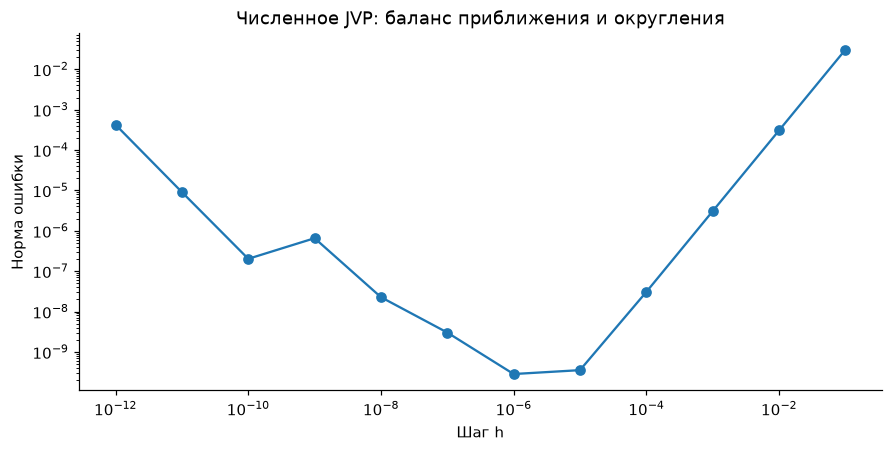

In [14]:
v_jvp = np.array([1.0, -2.0])
exact_jvp = J_exact @ v_jvp
jvp_steps = np.logspace(-1, -12, 12)
numerical_jvps = np.array(
    [
        (
            vector_function(x_star + step * v_jvp / 2)
            - vector_function(x_star - step * v_jvp / 2)
        )
        / step
        for step in jvp_steps
    ]
)
jvp_errors = np.linalg.norm(numerical_jvps - exact_jvp, axis=1)
print("Точное JVP:", exact_jvp, "форма:", exact_jvp.shape)
show_table(
    ["h", "Норма ошибки JVP"],
    [
        [f"{step:.0e}", f"{error:.3e}"]
        for step, error in zip(jvp_steps, jvp_errors, strict=True)
    ],
)
best_jvp_index = int(np.argmin(jvp_errors))
print(
    "Лучший шаг на сетке:",
    jvp_steps[best_jvp_index],
    "ошибка:",
    jvp_errors[best_jvp_index],
)
verification_errors["5.2 JVP best"] = float(jvp_errors.min())
np.testing.assert_allclose(numerical_jvps[4], exact_jvp, atol=1e-7, rtol=0)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.loglog(jvp_steps, jvp_errors, "o-")
ax.set(
    title="Численное JVP: баланс приближения и округления",
    xlabel="Шаг h",
    ylabel="Норма ошибки",
)
save_figure(fig, "04_jvp_error.png")

### Задание 5.3. VJP и производная композиции

Сначала для $\mathbf u=(1,2,-1)^{\mathsf T}$ вычислите $\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)$. Затем определите

$$
g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2,
\qquad
\mathbf c=(0,1,1)^{\mathsf T},
\qquad
h(\mathbf x)=g(\mathbf f(\mathbf x)).
$$

- **[Бумага]** Найдите $\nabla_{\mathbf z}g$ и $\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g$ в точке $\mathbf x_*$.
- **[Markdown]** Проверьте размерности каждого множителя и результата цепного правила.
- **[Python]** Сравните аналитический градиент композиции с `central_gradient`.
- **[Интерпретация]** Объясните, как VJP передаёт чувствительность одного скалярного результата ко всем входным координатам.


#### Решение 5.3

Для $\mathbf u=(1,2,-1)^{\mathsf T}$:
$$\mathbf u^{\mathsf T}J_*=(2+2e,-2e)\in\mathbb R^{1\times2}.$$
У $g(\mathbf z)=\frac12\sum_i(z_i-c_i)^2$
$$\nabla_{\mathbf z}g=\mathbf z-\mathbf c\in\mathbb R^{3\times1}.$$
При $\mathbf x_*$ имеем $\mathbf f-\mathbf c=(1,e-1,-1)^{\mathsf T}$ и
$$\nabla_{\mathbf x}h=
\underbrace{J_*^{\mathsf T}}_{2\times3}
\underbrace{(\mathbf f(\mathbf x_*)-\mathbf c)}_{3\times1}
=\begin{pmatrix}2+e^2-e\\e-e^2\end{pmatrix}\in\mathbb R^{2\times1}.$$
Значение $h(\mathbf x_*)=1+\frac12(e-1)^2$.
Транспонированный VJP передаёт чувствительность скалярного результата
от трёх промежуточных выходов к двум исходным координатам.
В VJP $\mathbf u$ — произвольные веса; в производной композиции роль этих
весов играет конкретный градиент $\mathbf f-\mathbf c$.


In [15]:
u_vjp = np.array([1.0, 2.0, -1.0])
c_target = np.array([0.0, 1.0, 1.0])
exact_vjp = u_vjp.reshape(1, -1) @ J_exact


def composition_h(point):
    """Вычислить скалярную композицию g(f(x))."""
    residual = vector_function(point) - c_target
    return 0.5 * np.dot(residual, residual)


def composition_gradient(point):
    """Применить цепное правило через транспонированный якобиан."""
    return jacobian_exact(point).T @ (vector_function(point) - c_target)


composition_exact = composition_gradient(x_star)
composition_numerical = central_gradient(composition_h, x_star)
print("u^T J:", exact_vjp, "форма:", exact_vjp.shape)
print("h(x*):", composition_h(x_star))
print("Градиент композиции:", composition_exact)
print("Центральный градиент:", composition_numerical)
verification_errors["5.3 composition"] = float(
    np.linalg.norm(composition_exact - composition_numerical)
)
print("Норма ошибки:", verification_errors["5.3 composition"])
np.testing.assert_allclose(composition_numerical, composition_exact, atol=1e-8, rtol=0)

u^T J: [[ 7.436563657 -5.436563657]] форма: (1, 2)
h(x*): 2.4762462210062797
Градиент композиции: [ 6.67077427 -4.67077427]
Центральный градиент: [ 6.670774271 -4.670774271]
Норма ошибки: 8.15363047149833e-10


## 6. Гессиан и кривизна


### Короткая теория

Гессиан дважды дифференцируемой функции $f:\mathbb R^n\to\mathbb R$ — якобиан градиента:

$$
\mathbf H_f(\mathbf x)=\nabla^2f(\mathbf x)
=\begin{pmatrix}
\frac{\partial^2f}{\partial x_1^2}&\cdots&\frac{\partial^2f}{\partial x_1\partial x_n}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2f}{\partial x_n\partial x_1}&\cdots&\frac{\partial^2f}{\partial x_n^2}
\end{pmatrix}.
$$

В стационарной точке положительно определённый гессиан указывает на локальный минимум, отрицательно определённый — на максимум, а неопределённый — на седловую точку. См. [гессиан, с. 41–42](linear-algebra.pdf#page=41), [положительно определённые матрицы, с. 13](linear-algebra.pdf#page=13) и [геометрию квадратичных форм, с. 27](linear-algebra.pdf#page=27).

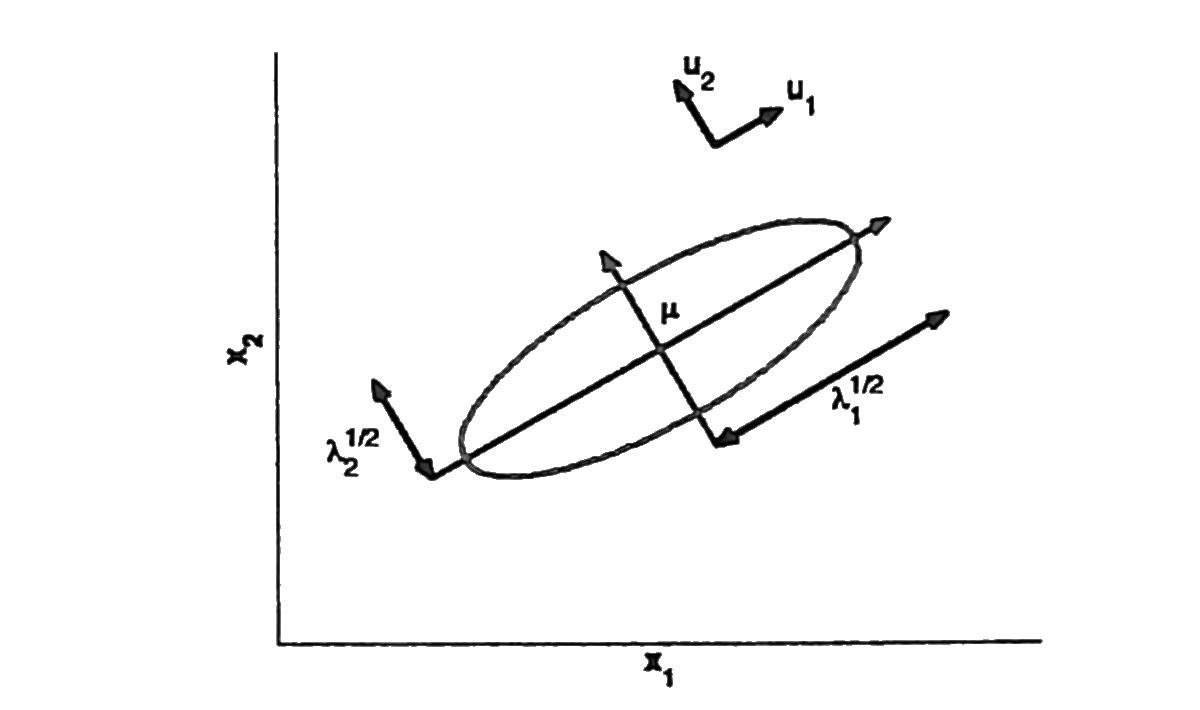

*Собственные направления симметричной матрицы задают главные направления кривизны квадратичной формы.*


### Задание 6.1. Положительная кривизна и минимум

Источник условия: [практикум, с. 142, задача 1](02-Высшая-математика-практикум.pdf#page=142).

Исследуйте на экстремум

$$
z=2x^2+y^2+x-3y+2xy.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, его определитель и собственные значения.
- **[Markdown]** Классифицируйте точку и вычислите значение функции.
- **[Python]** Проверьте решение, постройте линии уровня и отметьте стационарную точку.
- **[Интерпретация]** Свяжите положительные собственные значения с ростом функции во всех достаточно малых направлениях от минимума.


#### Решение 6.1

Стационарные точки определяются системой
$$z_x=4x+2y+1=0,\qquad z_y=2y+2x-3=0.$$
Деление второго равенства на 2 даёт $x+y=3/2$,
первого — $2x+y=-1/2$. Вычитая, получаем
$$x_*=-2,\qquad y_*=7/2.$$
Гессиан постоянен:
$$H=\begin{pmatrix}4&2\\2&2\end{pmatrix},\quad
\det H=8-4=4,\quad \operatorname{tr}H=6.$$
Характеристический многочлен $\mu^2-6\mu+4$ даёт
$$\mu_{1,2}=3\pm\sqrt5>0.$$
Гессиан положительно определён, поэтому это строгий минимум.
Поскольку вся функция квадратичная, минимум также единственный глобальный:
$z(\mathbf x_*+\Delta)-z(\mathbf x_*)=\frac12\Delta^{\mathsf T}H\Delta>0$
для любого $\Delta\ne0$.
$$z(-2,7/2)=8+49/4-2-21/2-14=-25/4=-6.25.$$


Стационарная точка: [-2.   3.5]
Значение: -6.25
Гессиан:
 [[4. 2.]
 [2. 2.]] определитель: 4.0
Собственные значения: [0.763932023 5.236067977]
Норма численного градиента: 0.0


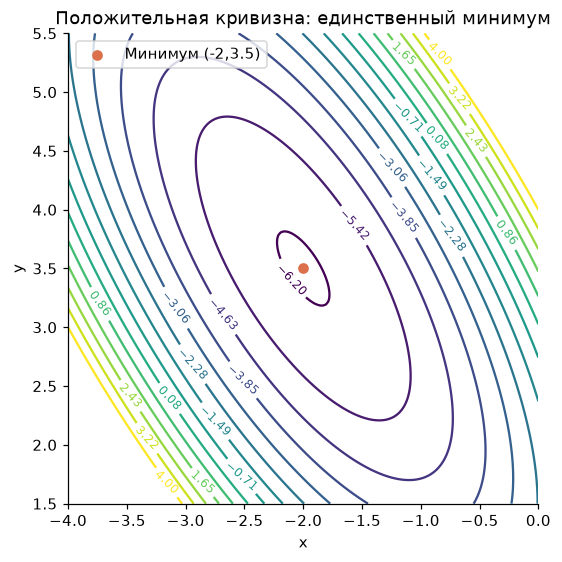

In [16]:
def minimum_function(point):
    """Вычислить функцию с положительно определённым гессианом."""
    x, y = point
    return 2 * x**2 + y**2 + x - 3 * y + 2 * x * y


minimum_point = np.array([-2.0, 3.5])
minimum_hessian = np.array([[4.0, 2.0], [2.0, 2.0]])
minimum_eigenvalues = np.linalg.eigvalsh(minimum_hessian)
minimum_gradient_numerical = central_gradient(minimum_function, minimum_point)
print("Стационарная точка:", minimum_point)
print("Значение:", minimum_function(minimum_point))
print("Гессиан:\n", minimum_hessian, "определитель:", np.linalg.det(minimum_hessian))
print("Собственные значения:", minimum_eigenvalues)
print("Норма численного градиента:", np.linalg.norm(minimum_gradient_numerical))
np.testing.assert_allclose(minimum_gradient_numerical, 0, atol=1e-8, rtol=0)
np.testing.assert_allclose(minimum_function(minimum_point), -6.25)
np.testing.assert_allclose(minimum_eigenvalues, [3 - np.sqrt(5), 3 + np.sqrt(5)])
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
gx, gy = np.meshgrid(np.linspace(-4, 0, 180), np.linspace(1.5, 5.5, 180))
contours = ax.contour(
    gx, gy, minimum_function((gx, gy)), levels=np.linspace(-6.2, 4, 14)
)
ax.clabel(contours, fontsize=8)
ax.scatter(*minimum_point, color="#db704b", label="Минимум (-2,3.5)")
ax.set(
    title="Положительная кривизна: единственный минимум",
    xlabel="x",
    ylabel="y",
    aspect="equal",
)
ax.legend()
save_figure(fig, "05_minimum.png")

### Задание 6.2. Неопределённая кривизна и седло

Источник условия: [практикум, с. 142, задача 3](02-Высшая-математика-практикум.pdf#page=142).

Исследуйте

$$
z=x^2-2y^2-4xy+3x.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, определитель и собственные значения.
- **[Markdown]** Покажите два направления, вдоль которых квадратичное изменение имеет разные знаки.
- **[Python]** Постройте линии уровня и трёхмерную поверхность около стационарной точки.
- **[Интерпретация]** Объясните, почему нулевой градиент ещё не гарантирует минимум.


#### Решение 6.2

$$z_x=2x-4y+3=0,\qquad z_y=-4y-4x=0.$$
Из второго равенства $y=-x$, поэтому $6x+3=0$ и
$\mathbf x_*=(-1/2,1/2)^{\mathsf T}$.
$$H=\begin{pmatrix}2&-4\\-4&-4\end{pmatrix},\quad
\det H=-8-16=-24,\quad \operatorname{tr}H=-2.$$
Характеристический многочлен $\mu^2+2\mu-24=(\mu-4)(\mu+6)$
имеет корни $4$ и $-6$. Гессиан неопределён, точка седловая.
$$z(-1/2,1/2)=1/4-1/2+1-3/2=-3/4.$$

Уже координатные направления показывают разные знаки:
$$z(\mathbf x_*+t\mathbf e_1)-z(\mathbf x_*)=t^2>0,\qquad
z(\mathbf x_*+t\mathbf e_2)-z(\mathbf x_*)=-2t^2<0.$$
При $t=0.1$ изменения равны $0.01$ и $-0.02$.
Нулевой градиент исключает только линейное изменение, но не определяет
знак квадратичного изменения, поэтому сам по себе не доказывает минимум.


Стационарная точка: [-0.5  0.5] значение: -0.75
Гессиан:
 [[ 2. -4.]
 [-4. -4.]] определитель: -23.999999999999993
Собственные значения: [-6.  4.]
Норма градиента: 5.551115123125782e-12
Изменения вдоль e1 и e2: [np.float64(0.009999999999999898), np.float64(-0.020000000000000018)]


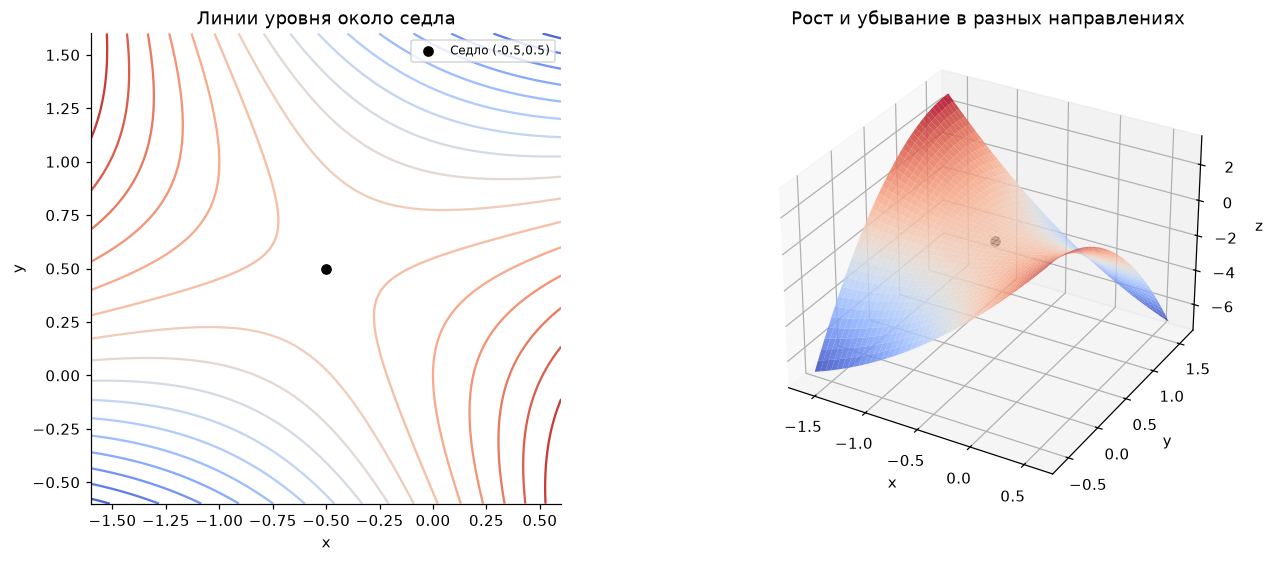

In [17]:
def saddle_function(point):
    """Вычислить квадратичную функцию с седловой точкой."""
    x, y = point
    return x**2 - 2 * y**2 - 4 * x * y + 3 * x


saddle_point = np.array([-0.5, 0.5])
saddle_hessian = np.array([[2.0, -4.0], [-4.0, -4.0]])
saddle_eigenvalues = np.linalg.eigvalsh(saddle_hessian)
saddle_gradient_numerical = central_gradient(saddle_function, saddle_point)
directional_changes = [
    saddle_function(saddle_point + 0.1 * direction) - saddle_function(saddle_point)
    for direction in np.eye(2)
]
print("Стационарная точка:", saddle_point, "значение:", saddle_function(saddle_point))
print("Гессиан:\n", saddle_hessian, "определитель:", np.linalg.det(saddle_hessian))
print("Собственные значения:", saddle_eigenvalues)
print("Норма градиента:", np.linalg.norm(saddle_gradient_numerical))
print("Изменения вдоль e1 и e2:", directional_changes)
np.testing.assert_allclose(saddle_gradient_numerical, 0, atol=1e-8, rtol=0)
np.testing.assert_allclose(saddle_eigenvalues, [-6, 4])
np.testing.assert_allclose(directional_changes, [0.01, -0.02])
fig = plt.figure(figsize=(12, 5), layout="constrained")
ax_contour = fig.add_subplot(1, 2, 1)
ax_surface = fig.add_subplot(1, 2, 2, projection="3d")
gx, gy = np.meshgrid(np.linspace(-1.6, 0.6, 120), np.linspace(-0.6, 1.6, 120))
surface_values = saddle_function((gx, gy))
ax_contour.contour(gx, gy, surface_values, levels=18, cmap="coolwarm")
ax_contour.scatter(*saddle_point, color="black", label="Седло (-0.5,0.5)")
ax_contour.set(title="Линии уровня около седла", xlabel="x", ylabel="y", aspect="equal")
ax_contour.legend(fontsize=8)
ax_surface.plot_surface(gx, gy, surface_values, cmap="coolwarm", alpha=0.85)
ax_surface.scatter(*saddle_point, saddle_function(saddle_point), color="black", s=35)
ax_surface.set(
    title="Рост и убывание в разных направлениях", xlabel="x", ylabel="y", zlabel="z"
)
save_figure(fig, "06_saddle.png")

### Задание 6.3. Квадратичная модель и HVP

Пусть

$$
\varphi(x,y)=e^{x+2y}+x^2,
\qquad \mathbf x_0=(0,0)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla\varphi(\mathbf x_0)$, $\mathbf H_\varphi(\mathbf x_0)$ и второе приближение

  $$
  \varphi(\mathbf x_0+\Delta)
  \approx \varphi(\mathbf x_0)
  +\nabla\varphi(\mathbf x_0)^{\mathsf T}\Delta
  +\frac12\Delta^{\mathsf T}\mathbf H_\varphi(\mathbf x_0)\Delta
  $$

  для $\Delta=(0.1,0.1)^{\mathsf T}$.
- **[Markdown]** Для $\mathbf v=(1,-1)^{\mathsf T}$ вычислите $\mathbf H\mathbf v$.
- **[Python]** Проверьте HVP центральной разностью градиента и сравните точное значение функции с линейным и квадратичным приближениями при уменьшающемся масштабе $\Delta$.
- **[Интерпретация]** Объясните, какую дополнительную информацию даёт квадратичный член по сравнению с одним градиентом.


#### Решение 6.3

Обозначим $s=x+2y$. Тогда
$$\nabla\varphi=\begin{pmatrix}e^s+2x\\2e^s\end{pmatrix},\qquad
H_\varphi=\begin{pmatrix}e^s+2&2e^s\\2e^s&4e^s\end{pmatrix}.$$
В нуле $\varphi_0=1$, $\nabla\varphi_0=(1,2)^{\mathsf T}$,
$H_0=\begin{pmatrix}3&2\\2&4\end{pmatrix}$.
Для $\Delta=(0.1,0.1)^{\mathsf T}$:
$$\nabla\varphi_0^{\mathsf T}\Delta=0.3,\quad
\frac12\Delta^{\mathsf T}H_0\Delta
=\frac12(0.03+0.04+0.04)=0.055.$$
Линейное приближение равно $1.3$, квадратичное — $1.355$,
точное значение $e^{0.3}+0.01\approx1.359858808$.
Для $\mathbf v=(1,-1)^{\mathsf T}$:
$$H_0\mathbf v=\begin{pmatrix}1\\-2\end{pmatrix}\in\mathbb R^{2\times1}.$$
Это изменение градиента, проверяемое разностью
$[\nabla\varphi(h\mathbf v)-\nabla\varphi(-h\mathbf v)]/(2h)$.
При замене $\Delta$ на $a\Delta$ ошибка линейной модели имеет порядок $a^2$,
а квадратичной — $a^3$: квадратичный член учитывает локальное изменение градиента.


Градиент: [1. 2.] гессиан:
 [[3. 2.]
 [2. 4.]]
Точное HVP: [ 1. -2.] численное: [ 1. -2.]
Норма ошибки HVP: 2.6228229407138406e-11


| Масштаб | Точное значение | Линейное | Квадратичное | Ошибка лин. | Ошибка квадр. |
| --- | --- | --- | --- | --- | --- |
| 1.0 | 1.359858808 | 1.300000000 | 1.355000000 | 5.986e-02 | 4.859e-03 |
| 0.5 | 1.164334243 | 1.150000000 | 1.163750000 | 1.433e-02 | 5.842e-04 |
| 0.25 | 1.078509151 | 1.075000000 | 1.078437500 | 3.509e-03 | 7.165e-05 |
| 0.125 | 1.038368247 | 1.037500000 | 1.038359375 | 8.682e-04 | 8.872e-06 |
| 0.0625 | 1.018965948 | 1.018750000 | 1.018964844 | 2.159e-04 | 1.104e-06 |

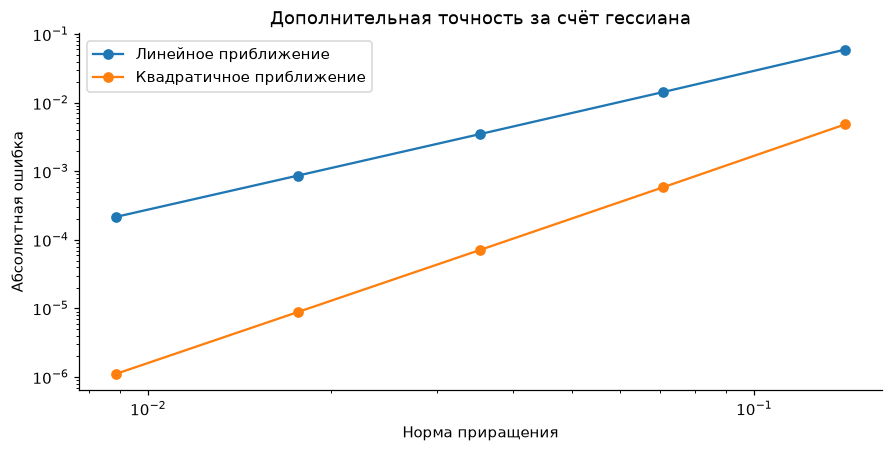

In [18]:
def phi(point):
    """Вычислить экспоненциально-квадратичную функцию."""
    x, y = point
    return np.exp(x + 2 * y) + x**2


def phi_gradient(point):
    """Вернуть аналитический градиент phi."""
    x, y = point
    exponential = np.exp(x + 2 * y)
    return np.array([exponential + 2 * x, 2 * exponential])


def phi_hessian(point):
    """Вернуть аналитический гессиан phi."""
    x, y = point
    exponential = np.exp(x + 2 * y)
    return np.array(
        [[exponential + 2, 2 * exponential], [2 * exponential, 4 * exponential]]
    )


phi_base = np.zeros(2)
phi_delta = np.array([0.1, 0.1])
v_hvp = np.array([1.0, -1.0])
phi_gradient_base = phi_gradient(phi_base)
phi_hessian_base = phi_hessian(phi_base)
exact_hvp = phi_hessian_base @ v_hvp
h = 1e-5
numerical_hvp = (
    phi_gradient(phi_base + h * v_hvp) - phi_gradient(phi_base - h * v_hvp)
) / (2 * h)
print("Градиент:", phi_gradient_base, "гессиан:\n", phi_hessian_base)
print("Точное HVP:", exact_hvp, "численное:", numerical_hvp)
verification_errors["6.3 HVP"] = float(np.linalg.norm(exact_hvp - numerical_hvp))
print("Норма ошибки HVP:", verification_errors["6.3 HVP"])
np.testing.assert_allclose(numerical_hvp, exact_hvp, atol=1e-8, rtol=0)
approximation_rows = []
scales = np.array([1.0, 0.5, 0.25, 0.125, 0.0625])
phi_linear_errors, phi_quadratic_errors = [], []
for scale in scales:
    increment = scale * phi_delta
    exact_value = phi(phi_base + increment)
    linear_value = phi(phi_base) + phi_gradient_base @ increment
    quadratic_value = linear_value + 0.5 * increment @ phi_hessian_base @ increment
    linear_error = abs(exact_value - linear_value)
    quadratic_error = abs(exact_value - quadratic_value)
    phi_linear_errors.append(linear_error)
    phi_quadratic_errors.append(quadratic_error)
    approximation_rows.append(
        [
            scale,
            f"{exact_value:.9f}",
            f"{linear_value:.9f}",
            f"{quadratic_value:.9f}",
            f"{linear_error:.3e}",
            f"{quadratic_error:.3e}",
        ]
    )
show_table(
    [
        "Масштаб",
        "Точное значение",
        "Линейное",
        "Квадратичное",
        "Ошибка лин.",
        "Ошибка квадр.",
    ],
    approximation_rows,
)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.loglog(
    scales * np.linalg.norm(phi_delta),
    phi_linear_errors,
    "o-",
    label="Линейное приближение",
)
ax.loglog(
    scales * np.linalg.norm(phi_delta),
    phi_quadratic_errors,
    "o-",
    label="Квадратичное приближение",
)
ax.set(
    title="Дополнительная точность за счёт гессиана",
    xlabel="Норма приращения",
    ylabel="Абсолютная ошибка",
)
ax.legend()
save_figure(fig, "07_taylor_approximations.png")

## 7. Матричное дифференцирование


### Короткая теория

Для векторного аргумента полезны тождества

$$
\frac{\partial(\mathbf a^{\mathsf T}\mathbf x)}{\partial\mathbf x}=\mathbf a,
\qquad
\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}
=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x.
$$

Для матричного аргумента производная скалярной функции имеет ту же форму, что и матрица:

$$
\left(\frac{\partial f}{\partial\mathbf X}\right)_{ij}
=\frac{\partial f}{\partial X_{ij}}.
$$

В частности,

$$
\frac{\partial}{\partial\mathbf X}
(\mathbf a^{\mathsf T}\mathbf X\mathbf b)
=\mathbf a\mathbf b^{\mathsf T},
\qquad
\frac{\partial}{\partial\mathbf X}
\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A.
$$

См. [векторные градиенты, с. 42](linear-algebra.pdf#page=42) и [матричные и следовые тождества, с. 42–43](linear-algebra.pdf#page=42).


### Задание 7.1. Линейно-квадратичная форма

Для

$$
f(\mathbf x)=\mathbf a^{\mathsf T}\mathbf x+mathbf x^{\mathsf T}\mathbf A\mathbf x,
$$

$$
\mathbf A=\begin{pmatrix}2&-1\\3&1\end{pmatrix},
\quad
\mathbf a=\begin{pmatrix}1\\-2\end{pmatrix},
\quad
\mathbf x=\begin{pmatrix}2\\-1\end{pmatrix},
$$

найдите значение, градиент и гессиан.

- **[Бумага]** Сначала раскройте выражение покоординатно, затем примените матричное тождество.
- **[Markdown]** Объясните появление симметричной части $\mathbf A+\mathbf A^{\mathsf T}$.
- **[Python]** Проверьте градиент и гессиан конечными разностями.
- **[Интерпретация]** Покажите, что кососимметричная часть $\mathbf A$ не влияет на $\mathbf x^{\mathsf T}\mathbf A\mathbf x$.


#### Решение 7.1

Сначала раскроем выражение при $\mathbf x=(x_1,x_2)^{\mathsf T}$:
$$f=x_1-2x_2+2x_1^2-x_1x_2+3x_1x_2+x_2^2
=x_1-2x_2+2x_1^2+2x_1x_2+x_2^2.$$
В точке $(2,-1)$ значение $f=2+2+8-4+1=9$.
Покомпонентное дифференцирование даёт
$$\nabla f=\begin{pmatrix}1+4x_1+2x_2\\-2+2x_1+2x_2\end{pmatrix},\qquad
\nabla f(2,-1)=\begin{pmatrix}7\\0\end{pmatrix}.$$
Матричное тождество даёт тот же результат:
$$\nabla f=\mathbf a+(A+A^{\mathsf T})\mathbf x,\qquad
H_f=A+A^{\mathsf T}=\begin{pmatrix}4&2\\2&2\end{pmatrix}\in\mathbb R^{2\times2}.$$
Симметричная часть $A_s=(A+A^{\mathsf T})/2$ равна
$\begin{pmatrix}2&1\\1&1\end{pmatrix}$, кососимметричная
$A_a=(A-A^{\mathsf T})/2=\begin{pmatrix}0&-2\\2&0\end{pmatrix}$.
Скаляр $q=\mathbf x^{\mathsf T}A_a\mathbf x$ равен собственному
транспонированию, то есть $q=\mathbf x^{\mathsf T}A_a^{\mathsf T}\mathbf x=-q$,
откуда $q=0$. Поэтому квадратичная форма зависит только от $A_s$.


In [19]:
def central_hessian(function, point, h=1e-3):
    """Вычислить гессиан скалярной функции центральными разностями."""
    point = np.asarray(point, dtype=float)
    hessian = np.zeros((point.size, point.size))
    basis = np.eye(point.size)
    value = function(point)
    for i in range(point.size):
        direction_i = h * basis[i]
        hessian[i, i] = (
            function(point + direction_i) - 2 * value + function(point - direction_i)
        ) / h**2
        for j in range(i + 1, point.size):
            direction_j = h * basis[j]
            mixed = (
                function(point + direction_i + direction_j)
                - function(point + direction_i - direction_j)
                - function(point - direction_i + direction_j)
                + function(point - direction_i - direction_j)
            ) / (4 * h**2)
            hessian[i, j] = mixed
            hessian[j, i] = mixed
    return hessian


A_quad = np.array([[2, -1], [3, 1]], dtype=float)
a_quad = np.array([1.0, -2.0])
x_quad = np.array([2.0, -1.0])


def linear_quadratic(point):
    """Вычислить линейно-квадратичную форму с несимметричной A."""
    return a_quad @ point + point @ A_quad @ point


value_quad = linear_quadratic(x_quad)
gradient_quad = a_quad + (A_quad + A_quad.T) @ x_quad
hessian_quad = A_quad + A_quad.T
gradient_quad_numerical = central_gradient(linear_quadratic, x_quad)
hessian_quad_numerical = central_hessian(linear_quadratic, x_quad)
antisymmetric = (A_quad - A_quad.T) / 2
print("Значение:", value_quad, "градиент:", gradient_quad, "гессиан:\n", hessian_quad)
print(
    "Численный градиент:",
    gradient_quad_numerical,
    "численный гессиан:\n",
    hessian_quad_numerical,
)
print("Вклад кососимметричной части:", x_quad @ antisymmetric @ x_quad)
verification_errors["7.1 gradient"] = float(
    np.linalg.norm(gradient_quad - gradient_quad_numerical)
)
verification_errors["7.1 Hessian"] = float(
    np.linalg.norm(hessian_quad - hessian_quad_numerical, ord="fro")
)
print(
    "Нормы ошибок градиента и гессиана:",
    verification_errors["7.1 gradient"],
    verification_errors["7.1 Hessian"],
)
np.testing.assert_allclose(gradient_quad_numerical, [7, 0], atol=1e-8, rtol=0)
np.testing.assert_allclose(hessian_quad_numerical, hessian_quad, atol=1e-7, rtol=0)
np.testing.assert_allclose(x_quad @ antisymmetric @ x_quad, 0)

Значение: 9.0 градиент: [7. 0.] гессиан:
 [[4. 2.]
 [2. 2.]]
Численный градиент: [ 7. -0.] численный гессиан:
 [[3.999999999 2.         ]
 [2.          2.000000002]]
Вклад кососимметричной части: 0.0
Нормы ошибок градиента и гессиана: 1.2663586786024652e-10 2.400542657403452e-09


### Задание 7.2. Производная по матрице

Пусть

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b,
\quad
\mathbf a=(1,-2)^{\mathsf T},
\quad
\mathbf b=(3,1,-1)^{\mathsf T},
$$

$$
\mathbf M=
\begin{pmatrix}1&2&0\\-1&3&4\end{pmatrix}.
$$

- **[Бумага]** Раскройте $s=\sum_i\sum_j a_iM_{ij}b_j$ и найдите каждую $\partial s/\partial M_{ij}$.
- **[Markdown]** Сверните результат в $\mathbf a\mathbf b^{\mathsf T}$ и перепишите скаляр через след.
- **[Python]** Изменяйте каждый элемент $M_{ij}$ отдельно и сравните численный градиент с внешним произведением.
- **[Интерпретация]** Объясните, почему форма градиента совпадает с формой матрицы параметров.


#### Решение 7.2

Здесь $\mathbf a\in\mathbb R^{2\times1}$,
$M\in\mathbb R^{2\times3}$, $\mathbf b\in\mathbb R^{3\times1}$,
$s\in\mathbb R$. Раскрытие суммы даёт
$$s=1\cdot1\cdot3+1\cdot2\cdot1+1\cdot0\cdot(-1)
+(-2)\cdot(-1)\cdot3+(-2)\cdot3\cdot1+(-2)\cdot4\cdot(-1)=13.$$
Поскольку $s=\sum_{i,j}a_iM_{ij}b_j$, по каждому элементу
$$\frac{\partial s}{\partial M_{ij}}=a_ib_j.$$
Поэтому
$$\nabla_Ms=\mathbf a\mathbf b^{\mathsf T}
=\begin{pmatrix}3&1&-1\\-6&-2&2\end{pmatrix}\in\mathbb R^{2\times3}.$$
Через след:
$$s=\operatorname{tr}(\mathbf b\mathbf a^{\mathsf T}M)
=\operatorname{tr}((\mathbf a\mathbf b^{\mathsf T})^{\mathsf T}M),\qquad
ds=\operatorname{tr}((\nabla_Ms)^{\mathsf T}dM).$$
Градиент имеет по одному числу на каждый независимый параметр $M_{ij}$,
поэтому его форма совпадает с формой матрицы параметров.


In [20]:
a_matrix = np.array([1.0, -2.0])
b_matrix = np.array([3.0, 1.0, -1.0])
M_parameter = np.array([[1, 2, 0], [-1, 3, 4]], dtype=float)


def matrix_scalar(matrix):
    """Вычислить скаляр a.T @ M @ b."""
    return a_matrix @ matrix @ b_matrix


matrix_gradient_exact = np.outer(a_matrix, b_matrix)
matrix_gradient_numerical = central_gradient(matrix_scalar, M_parameter)
print("s:", matrix_scalar(M_parameter))
print("Градиент через внешнее произведение:\n", matrix_gradient_exact)
print("Поэлементная численная проверка:\n", matrix_gradient_numerical)
print("Через след:", np.trace(matrix_gradient_exact.T @ M_parameter))
verification_errors["7.2 matrix gradient"] = float(
    np.linalg.norm(matrix_gradient_exact - matrix_gradient_numerical, ord="fro")
)
print("Норма ошибки:", verification_errors["7.2 matrix gradient"])
np.testing.assert_allclose(
    matrix_gradient_numerical, matrix_gradient_exact, atol=1e-8, rtol=0
)
np.testing.assert_allclose(matrix_scalar(M_parameter), 13)

s: 13.0
Градиент через внешнее произведение:
 [[ 3.  1. -1.]
 [-6. -2.  2.]]
Поэлементная численная проверка:
 [[ 3.  1. -1.]
 [-6. -2.  2.]]
Через след: 13.0
Норма ошибки: 1.8668665621941835e-10


### Задание 7.3. Сумма потерь, след и матричный градиент

Для общего пакета данных определим

$$
Q(\mathbf W)=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2.
$$

- **[Бумага]** Запишите $Q$ тремя способами:

  $$
  Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K
  \left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2,
  $$

  через норму Фробениуса и через след.
- **[Markdown]** Выведите по индексам

  $$
  \nabla_{\mathbf W}Q
  =\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)
  $$

  и действие гессиана на матрицу-направление $\Delta\mathbf W$.
- **[Python]** Вычислите $Q(\mathbf W_0)$, градиент и проверьте каждый элемент конечными разностями.
- **[Интерпретация]** Сопоставьте индексы $d,k$ у градиента индексам параметра $W_{dk}$.


#### Решение 7.3

При $R=XW-Y\in\mathbb R^{N\times K}$ три записи функции:
$$Q=\frac1{2N}\sum_{n=1}^{N}\sum_{k=1}^{K}
\left(\sum_{d=1}^{D}X_{nd}W_{dk}-Y_{nk}\right)^2
=\frac1{2N}\lVert R\rVert_F^2
=\frac1{2N}\operatorname{tr}(R^{\mathsf T}R).$$
Для фиксированного $W_{dk}$ ненулевые вклады имеют тот же выходной индекс $k$:
$$\frac{\partial Q}{\partial W_{dk}}
=\frac1{2N}\sum_n2R_{nk}X_{nd}
=\frac1N\sum_nX_{nd}R_{nk}.$$
Поэтому $\nabla_WQ=X^{\mathsf T}(XW-Y)/N\in\mathbb R^{3\times2}$.
Для возмущения $\Delta W\in\mathbb R^{3\times2}$
$$H_Q[\Delta W]=\frac1N X^{\mathsf T}X\Delta W\in\mathbb R^{3\times2}.$$
Полный гессиан по шести параметрам строить не нужно: достаточно его действия.
При $W_0$ остаток равен
$$R_0=\begin{pmatrix}0.5&-1.3\\-0.8&0.2\\0&-0.6\\0&-0.2\end{pmatrix},$$
$$Q(W_0)=\frac{0.25+1.69+0.64+0.04+0.36+0.04}{8}=0.3775,$$
$$\nabla_WQ(W_0)=\begin{pmatrix}0.125&-0.425\\-0.2&-0.2\\-0.325&0.325\end{pmatrix}.$$
Индексы $d,k$ результата относятся к входной координате и выходу,
как и у параметра $W_{dk}$; суммируется только индекс наблюдения $n$.


In [21]:
def matrix_least_squares(W):
    """Вычислить среднюю квадратичную потерю без сигмоиды и регуляризации."""
    residual = X_data @ W - Y_data
    return 0.5 * np.sum(residual**2) / len(X_data)


def matrix_least_squares_gradient(W):
    """Вернуть аналитический градиент матричной квадратичной потери."""
    return X_data.T @ (X_data @ W - Y_data) / len(X_data)


def matrix_least_squares_hvp(delta_W):
    """Применить гессиан квадратичной потери к матрице-направлению."""
    return X_data.T @ X_data @ delta_W / len(X_data)


least_squares_exact = matrix_least_squares_gradient(W_initial)
least_squares_numerical = central_gradient(matrix_least_squares, W_initial)
delta_W = np.array([[1, 0], [0, -1], [1, 1]], dtype=float)
least_squares_hvp_exact = matrix_least_squares_hvp(delta_W)
h = 1e-5
least_squares_hvp_numerical = (
    matrix_least_squares_gradient(W_initial + h * delta_W)
    - matrix_least_squares_gradient(W_initial - h * delta_W)
) / (2 * h)
print("Q(W0):", matrix_least_squares(W_initial))
print("Градиент:\n", least_squares_exact, "численный:\n", least_squares_numerical)
print("Направление:\n", delta_W, "действие гессиана:\n", least_squares_hvp_exact)
verification_errors["7.3 matrix gradient"] = float(
    np.linalg.norm(least_squares_exact - least_squares_numerical, ord="fro")
)
verification_errors["7.3 HVP"] = float(
    np.linalg.norm(least_squares_hvp_exact - least_squares_hvp_numerical, ord="fro")
)
print("Норма ошибки градиента:", verification_errors["7.3 matrix gradient"])
print("Норма ошибки HVP:", verification_errors["7.3 HVP"])
np.testing.assert_allclose(matrix_least_squares(W_initial), 0.3775)
np.testing.assert_allclose(
    least_squares_numerical, least_squares_exact, atol=1e-8, rtol=0
)
np.testing.assert_allclose(
    least_squares_hvp_numerical, least_squares_hvp_exact, atol=1e-8, rtol=0
)

Q(W0): 0.3775
Градиент:
 [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]] численный:
 [[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
Направление:
 [[ 1.  0.]
 [ 0. -1.]
 [ 1.  1.]] действие гессиана:
 [[ 0.25 -0.25]
 [ 0.5  -0.75]
 [ 0.25  0.  ]]
Норма ошибки градиента: 2.0196907493225983e-12
Норма ошибки HVP: 5.345321836320918e-12


## 8. Сквозная составная функция


### Короткая теория

Для сигмоиды

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).
$$

В матричном выражении нелинейная функция применяется поэлементно. Чтобы не смешивать матричное и поэлементное умножение, будем обозначать последнее символом $\odot$.

Цепное правило для композиции применяется от скалярного результата к каждому промежуточному аргументу. Это та же идея, что произведение якобианов и VJP на [с. 41](linear-algebra.pdf#page=41), но записанная сразу в формах нужных массивов.


### Задание 8.1. Прямое вычисление и размерности

- **[Бумага]** Для элемента $Z_{nk}$ запишите

  $$
  Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k.
  $$

  Затем запишите $H_{nk}$ и $\mathcal L$ как суммы по индексам.
- **[Markdown]** Составьте таблицу объектов $\mathbf X,\mathbf W,\mathbf b,\mathbf Z,\mathbf H,\mathbf Y,\mathcal L$ с размерностями и типами.
- **[Python]** Выполните прямое вычисление с начальными параметрами. Для устойчивости ограничьте аргумент `exp` диапазоном `[-50, 50]`.
- **[Интерпретация]** Объясните, почему добавление $\mathbf b$ к каждой строке является расширением по строкам, а не матричным произведением двух исходных массивов.


#### Решение 8.1

Индексная запись прямого прохода:
$$Z_{nk}=\sum_{d=1}^{3}X_{nd}W_{dk}+b_k,\qquad
H_{nk}=\frac1{1+e^{-Z_{nk}}},$$
$$\mathcal L=\frac18\sum_{n=1}^{4}\sum_{k=1}^{2}(H_{nk}-Y_{nk})^2
+0.025\sum_{d=1}^{3}\sum_{k=1}^{2}W_{dk}^2.$$

| Объект | Тип | Математическая размерность | Форма NumPy |
|---|---|---|---|
| $X$ | Матрица входов | $4\times3$ | `(4,3)` |
| $W$ | Матрица параметров | $3\times2$ | `(3,2)` |
| $b$ | Вектор параметров | $2\times1$ | `(2,)` |
| $Z$ | Матрица линейных выходов | $4\times2$ | `(4,2)` |
| $H$ | Матрица выходов сигмоиды | $4\times2$ | `(4,2)` |
| $Y$ | Матрица целевых значений | $4\times2$ | `(4,2)` |
| $\mathcal L$ | Скаляр | $1$ | `()` |

Начальные параметры дают
$$Z_0=\begin{pmatrix}0.8&-0.7\\0&0.1\\0.7&-0.4\\0.2&0.5\end{pmatrix}.$$
Например, $Z_{11}=1\cdot0.2+0\cdot0.4+(-1)\cdot(-0.5)+0.1=0.8$.
Сумма квадратов весов равна $0.59$, регуляризация — $0.025\cdot0.59=0.01475$.
После поэлементной сигмоиды часть ошибки равна примерно $0.1204891043$,
полная функция — $0.1352391043$.

В NumPy выражение `X_data @ W + b` использует расширение формы `(2,)`
до каждой из четырёх строк. Это сложение с повторяемым вектором,
математически эквивалентное $XW+\mathbf1_4b^{\mathsf T}$,
а не произведение матрицы $XW$ на исходный вектор $b$.


In [22]:
Z_initial = X_data @ W_initial + b_initial
H_initial = sigmoid(Z_initial)
data_loss_initial = 0.5 * np.sum((H_initial - Y_data) ** 2) / len(X_data)
regularization_loss_initial = 0.5 * regularization * np.sum(W_initial**2)
loss_initial = data_loss_initial + regularization_loss_initial
print("Z:\n", Z_initial)
print("H:\n", H_initial)
print("Ошибка данных:", data_loss_initial)
print("Регуляризация:", regularization_loss_initial)
print("Полная L:", loss_initial)
for name, value in [
    ("X", X_data),
    ("W", W_initial),
    ("b", b_initial),
    ("Z", Z_initial),
    ("H", H_initial),
    ("Y", Y_data),
    ("L", loss_initial),
]:
    print(name, np.shape(value))
np.testing.assert_allclose(
    Z_initial, [[0.8, -0.7], [0, 0.1], [0.7, -0.4], [0.2, 0.5]], atol=1e-14, rtol=0
)
np.testing.assert_allclose(regularization_loss_initial, 0.01475)
assert np.max(np.abs(Z_initial)) < 50

Z:
 [[ 0.8 -0.7]
 [ 0.   0.1]
 [ 0.7 -0.4]
 [ 0.2  0.5]]
H:
 [[0.689974481 0.331812228]
 [0.5         0.524979187]
 [0.668187772 0.40131234 ]
 [0.549833997 0.622459331]]
Ошибка данных: 0.12048910430482579
Регуляризация: 0.014750000000000003
Полная L: 0.1352391043048258
X (4, 3)
W (3, 2)
b (2,)
Z (4, 2)
H (4, 2)
Y (4, 2)
L ()


### Задание 8.2. Распространение производных по композиции

Обозначьте $\mathbf R=\mathbf H-\mathbf Y$.

- **[Бумага]** Последовательно получите

  $$
  \mathbf G_H=\frac{1}{N}\mathbf R,
  \qquad
  \mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H),
  $$

  $$
  \nabla_{\mathbf W}\mathcal L
  =\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W,
  \qquad
  \nabla_{\mathbf b}\mathcal L
  =\mathbf G_Z^{\mathsf T}\mathbf1_N.
  $$
- **[Markdown]** После каждой строки подпишите размерность. Отдельно объясните происхождение $\lambda\mathbf W$.
- **[Python]** Реализуйте одну функцию, возвращающую $\mathcal L$, $\nabla_{\mathbf W}\mathcal L$ и $\nabla_{\mathbf b}\mathcal L$.
- **[Интерпретация]** Опишите вычисление производных как движение по композиции в порядке, обратном прямому вычислению значений.


#### Решение 8.2

Пусть $R=H-Y\in\mathbb R^{4\times2}$. Дифференцируем сумму квадратов:
$$[G_H]_{nk}=\frac{\partial\mathcal L}{\partial H_{nk}}
=\frac1{2N}\,2(H_{nk}-Y_{nk})=\frac1N R_{nk},\qquad G_H\in\mathbb R^{4\times2}.$$
Производная сигмоиды:
$$\sigma'(z)=\frac{e^{-z}}{(1+e^{-z})^2}=\sigma(z)(1-\sigma(z)).$$
Каждый $H_{nk}$ зависит только от соответствующего $Z_{nk}$, поэтому
$$G_Z=G_H\odot H\odot(1-H)\in\mathbb R^{4\times2}.$$
Из $\partial Z_{nk}/\partial W_{dk}=X_{nd}$ для соответствующего выхода $k$:
$$\frac{\partial\mathcal L}{\partial W_{dk}}
=\sum_nX_{nd}[G_Z]_{nk}+\lambda W_{dk},$$
$$\nabla_W\mathcal L=
\underbrace{X^{\mathsf T}}_{3\times4}\underbrace{G_Z}_{4\times2}
+\underbrace{\lambda W}_{3\times2}\in\mathbb R^{3\times2}.$$
Слагаемое $\lambda W$ получается из
$\partial(\lambda\sum_{d,k}W_{dk}^2/2)/\partial W_{dk}=\lambda W_{dk}$.
В регуляризации нет $b$, поэтому дополнительного слагаемого для него нет.
Поскольку $b_k$ прибавляется ко всем наблюдениям,
$$[\nabla_b\mathcal L]_k=\sum_n[G_Z]_{nk},\qquad
\nabla_b\mathcal L=\underbrace{G_Z^{\mathsf T}}_{2\times4}
\underbrace{\mathbf1_4}_{4\times1}\in\mathbb R^{2\times1}.$$

Прямой проход идёт от $W,b$ к $Z,H,\mathcal L$, обратный — от скалярной
потери к $G_H,G_Z$ и градиентам параметров. Полные якобианы всех элементов
при этом не строятся. Ограничение `clip` из защитной реализации сигмоиды
неактивно на рассматриваемых точках и траекториях, поэтому не меняет эти производные.


In [23]:
def objective_and_grad(W, b):
    """Вернуть потерю и аналитические градиенты при неактивном clip сигмоиды."""
    Z = X_data @ W + b
    H = sigmoid(Z)
    residual = H - Y_data
    loss = 0.5 * np.sum(residual**2) / len(X_data) + 0.5 * regularization * np.sum(W**2)
    grad_H = residual / len(X_data)
    grad_Z = grad_H * H * (1 - H)
    grad_W = X_data.T @ grad_Z + regularization * W
    grad_b = grad_Z.sum(axis=0)
    return loss, grad_W, grad_b


initial_loss, initial_grad_W, initial_grad_b = objective_and_grad(W_initial, b_initial)
print("L:", initial_loss, "форма:", np.shape(initial_loss))
print("Градиент W:\n", initial_grad_W, "форма:", initial_grad_W.shape)
print("Градиент b:", initial_grad_b, "форма:", initial_grad_b.shape)
assert initial_grad_W.shape == W_initial.shape
assert initial_grad_b.shape == b_initial.shape
np.testing.assert_allclose(initial_loss, loss_initial)

L: 0.1352391043048258 форма: ()
Градиент W:
 [[ 0.012146758 -0.024566216]
 [ 0.066950211 -0.001037811]
 [-0.035867231  0.046139949]] форма: (3, 2)
Градиент b: [ 0.045317442 -0.015682853] форма: (2,)


### Задание 8.3. Проверка каждого параметра

- **[Бумага]** Запишите центральную разность для одного элемента $W_{dk}$ и одного элемента $b_k$.
- **[Python]** Реализуйте универсальную численную проверку, поочерёдно возмущающую каждый элемент $\mathbf W$ и $\mathbf b$ при $h=10^{-6}$.
- **[Markdown]** Выведите аналитические и численные градиенты, максимальную абсолютную и относительную ошибки.
- **[Интерпретация]** Если проверка не проходит, перечислите порядок диагностики: коэффициент $1/N$, знак остатка, производная сигмоиды, транспонирование, сумма по строкам и регуляризация.


#### Решение 8.3

Обозначим $E^{(dk)}$ матрицу с единицей в позиции $(d,k)$ и нулями
в остальных позициях; $e^{(k)}$ — соответствующий базисный вектор.
При $h=10^{-6}$ проверяем каждый параметр отдельно:
$$\frac{\partial\mathcal L}{\partial W_{dk}}\approx
\frac{\mathcal L(W+hE^{(dk)},b)-\mathcal L(W-hE^{(dk)},b)}{2h},$$
$$\frac{\partial\mathcal L}{\partial b_k}\approx
\frac{\mathcal L(W,b+he^{(k)})-\mathcal L(W,b-he^{(k)})}{2h}.$$
Шесть весов и два смещения требуют $2(6+2)=16$ вычислений потери.
Проверка сравнивает восемь аналитических и численных компонент.
Для каждой компоненты используем абсолютную ошибку $|a-n|$ и
относительную $|a-n|/\max(10^{-12},|a|+|n|)$.
Ниже показаны обе матрицы градиентов, поэлементная таблица и максимальные ошибки;
требуемый порог абсолютной ошибки — $10^{-6}$.

Порядок диагностики при несовпадении:

1. Проверить множитель $1/N$, а не $1/(NK)$.
2. Проверить знак остатка: $H-Y$.
3. Убедиться, что есть множитель $H(1-H)$.
4. Проверить транспонирование в $X^{\mathsf T}G_Z$.
5. Для $b$ суммировать по наблюдениям, то есть по строкам.
6. Добавить $\lambda W$ только к градиенту весов.
7. Затем проверить шаг разности, формы массивов и неактивность защитного ограничения.

**Результат проверки:** максимальная абсолютная ошибка — около $7.29\cdot10^{-12}$, максимальная относительная — $3.16\cdot10^{-9}$. Все восемь компонент проходят требование $10^{-6}$.


In [24]:
def numerical_parameter_gradients(W, b, h=1e-6):
    """Проверить каждый элемент W и b центральной конечной разностью."""
    grad_W = central_gradient(lambda weights: objective_and_grad(weights, b)[0], W, h)
    grad_b = central_gradient(lambda bias: objective_and_grad(W, bias)[0], b, h)
    return grad_W, grad_b


numerical_grad_W, numerical_grad_b = numerical_parameter_gradients(W_initial, b_initial)
analytic_all = np.concatenate([initial_grad_W.ravel(), initial_grad_b])
numerical_all = np.concatenate([numerical_grad_W.ravel(), numerical_grad_b])
absolute_errors = np.abs(analytic_all - numerical_all)
relative_errors = absolute_errors / np.maximum(
    1e-12, np.abs(analytic_all) + np.abs(numerical_all)
)
max_absolute_error = float(absolute_errors.max())
max_relative_error = float(relative_errors.max())
verification_errors["8.3 max absolute"] = max_absolute_error
verification_errors["8.3 max relative"] = max_relative_error
print("Аналитический градиент W:\n", initial_grad_W)
print("Численный градиент W:\n", numerical_grad_W)
print("Аналитический градиент b:", initial_grad_b)
print("Численный градиент b:", numerical_grad_b)
parameter_names = [f"W[{i + 1},{j + 1}]" for i, j in np.ndindex(W_initial.shape)] + [
    "b[1]",
    "b[2]",
]
parameter_checks = [
    {
        "parameter": name,
        "analytic": float(analytic_all[i]),
        "numerical": float(numerical_all[i]),
        "absolute_error": float(absolute_errors[i]),
        "relative_error": float(relative_errors[i]),
    }
    for i, name in enumerate(parameter_names)
]
show_table(
    ["Параметр", "Аналитически", "Численно", "Абс. ошибка", "Отн. ошибка"],
    [
        [
            row["parameter"],
            f"{row['analytic']:.10f}",
            f"{row['numerical']:.10f}",
            f"{row['absolute_error']:.3e}",
            f"{row['relative_error']:.3e}",
        ]
        for row in parameter_checks
    ],
)
print("Максимальная абсолютная ошибка:", max_absolute_error)
print("Максимальная относительная ошибка:", max_relative_error)
print(
    "Норма ошибки объединённого градиента:",
    np.linalg.norm(analytic_all - numerical_all),
)
assert max_absolute_error < 1e-6
assert max_relative_error < 1e-6
with (RESULTS_DIR / "parameter_gradient_check.csv").open(
    "w", newline="", encoding="utf-8"
) as stream:
    writer = csv.DictWriter(stream, fieldnames=list(parameter_checks[0]))
    writer.writeheader()
    writer.writerows(parameter_checks)
display(
    Markdown(
        "**Проверка пройдена:** все восемь компонент согласуются с конечными разностями."
    )
)

Аналитический градиент W:
 [[ 0.012146758 -0.024566216]
 [ 0.066950211 -0.001037811]
 [-0.035867231  0.046139949]]
Численный градиент W:
 [[ 0.012146758 -0.024566216]
 [ 0.066950211 -0.001037811]
 [-0.035867231  0.046139949]]
Аналитический градиент b: [ 0.045317442 -0.015682853]
Численный градиент b: [ 0.045317442 -0.015682853]


| Параметр | Аналитически | Численно | Абс. ошибка | Отн. ошибка |
| --- | --- | --- | --- | --- |
| W[1,1] | 0.0121467575 | 0.0121467575 | 6.512e-12 | 2.680e-10 |
| W[1,2] | -0.0245662162 | -0.0245662163 | 7.289e-12 | 1.484e-10 |
| W[2,1] | 0.0669502114 | 0.0669502114 | 7.130e-14 | 5.325e-13 |
| W[2,2] | -0.0010378111 | -0.0010378111 | 6.558e-12 | 3.160e-09 |
| W[3,1] | -0.0358672308 | -0.0358672308 | 3.765e-12 | 5.249e-11 |
| W[3,2] | 0.0461399489 | 0.0461399489 | 5.767e-12 | 6.250e-11 |
| b[1] | 0.0453174422 | 0.0453174422 | 1.184e-12 | 1.307e-11 |
| b[2] | -0.0156828532 | -0.0156828532 | 2.886e-12 | 9.200e-11 |

Максимальная абсолютная ошибка: 7.289273351585024e-12
Максимальная относительная ошибка: 3.1597556217764285e-09
Норма ошибки объединённого градиента: 1.3989959143596012e-11


**Проверка пройдена:** все восемь компонент согласуются с конечными разностями.

## 9. Численная оптимизация


### Короткая теория

После проверки градиента параметры можно обновлять в направлении убывания:

$$
\mathbf W^{(r+1)}=\mathbf W^{(r)}-\eta\nabla_{\mathbf W}\mathcal L,
\qquad
\mathbf b^{(r+1)}=\mathbf b^{(r)}-\eta\nabla_{\mathbf b}\mathcal L,
$$

где $\eta>0$ — шаг. Производная локальна: слишком большой шаг может вывести параметры за область, где линейное приближение правильно предсказывает изменение функции.


### Задание 9.1. Шаг, траектория и устойчивость

- **[Бумага]** Используя начальный градиент, предскажите знак первого изменения $\mathcal L$ для достаточно малого $\eta$.
- **[Python]** Выполните 100 обновлений из одинаковой начальной точки для $\eta\in\{0.1,1,20\}$. Сохраните историю функции и нормы градиента. Постройте графики в логарифмическом масштабе.
- **[Markdown]** Для каждого шага укажите начальное и конечное значения, минимальное значение, номер лучшей итерации и наличие увеличений.
- **[Интерпретация]** Объясните различие между медленным устойчивым уменьшением, быстрым устойчивым уменьшением и нестабильной траекторией. Не делайте вывода только по последней точке — используйте всю историю.


#### Решение 9.1

Для достаточно малого $\eta>0$ первый порядок Тейлора даёт
$$\Delta\mathcal L\approx
-\eta\left(\lVert\nabla_W\mathcal L\rVert_F^2+
\lVert\nabla_b\mathcal L\rVert_2^2\right)<0,$$
поскольку начальный градиент ненулевой. Это локальное утверждение:
при большом шаге члены более высоких порядков могут изменить знак приращения.

Для каждого шага начинаем с копий тех же $W_0,b_0$ и выполняем ровно
100 обновлений. История хранит **100 значений после обновлений 1–100**,
а общее начальное значение хранится отдельно. На графиках добавлена
точка 0, чтобы явно показать одинаковое начало всех траекторий.
Это одновременно сохраняет требуемые 100 значений истории и все 100 обновлений.

Результат сравнения всей траектории:

- При $\eta=0.1$ потеря уменьшается медленно и монотонно:
  с $0.1352391043$ до $0.0857175420$; минимум наблюдается на шаге 100.
- При $\eta=1$ уменьшение также монотонно, но быстрее:
  конечная потеря $0.0731329220$, минимум на шаге 100.
- При $\eta=20$ потеря колеблется: лучший результат $0.1166819041$
  достигнут на шаге 4, после чего улучшение не сохраняется.
  После 100 шагов потеря $0.1653215087$, выше начальной;
  увеличение зафиксировано на 51 переходе.

После 100 обновлений нормы градиента составляют примерно $0.04209$,
$0.000970$ и $0.14058$ соответственно. Поэтому по этим экспериментам
шаг 1 даёт наиболее успешную наблюдаемую траекторию.
Для шага 20 речь идёт о колебательной неустойчивости на данном промежутке,
а не о доказанном неограниченном росте. Значение на последнем шаге
само по себе не описывает всю историю и не доказывает достижение глобального минимума.


Начальная потеря: 0.1352391043048258
Начальная норма градиента: 0.10463950563500042
Первое изменение для малого eta примерно: -0.010949426139537284 * eta


| Шаг | Начальная L | Конечная L | Минимальная L | Лучший шаг | Увеличений | Норма градиента |
| --- | --- | --- | --- | --- | --- | --- |
| 0.1 | 0.1352391043 | 0.0857175420 | 0.0857175420 | 100 | 0 | 0.042088 |
| 1.0 | 0.1352391043 | 0.0731329220 | 0.0731329220 | 100 | 0 | 0.000970 |
| 20.0 | 0.1352391043 | 0.1653215087 | 0.1166819041 | 4 | 51 | 0.140582 |

Максимальный |Z| на всех траекториях: 4.1825859202272255 < 50: clip неактивен


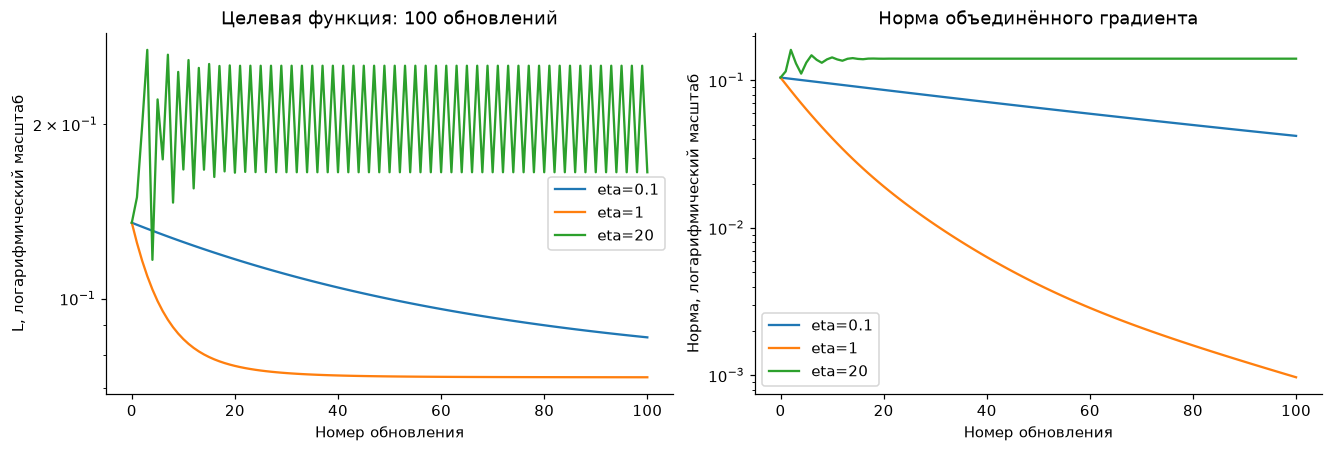

3414

In [25]:
learning_rates = [0.1, 1.0, 20.0]
iterations = 100
initial_gradient_norm = float(np.linalg.norm(analytic_all))
initial_gradient_squared_norm = initial_gradient_norm**2
print("Начальная потеря:", initial_loss)
print("Начальная норма градиента:", initial_gradient_norm)
print(
    "Первое изменение для малого eta примерно:", -initial_gradient_squared_norm, "* eta"
)
histories = {}
optimization_summary = []
optimization_records = []
final_parameters = {}
max_absolute_logit = float(np.max(np.abs(Z_initial)))
for learning_rate in learning_rates:
    W = W_initial.copy()
    b = b_initial.copy()
    start_loss, _, _ = objective_and_grad(W, b)
    np.testing.assert_allclose(start_loss, initial_loss)
    loss_history = []
    gradient_history = []
    for iteration in range(1, iterations + 1):
        _, grad_W, grad_b = objective_and_grad(W, b)
        W = W - learning_rate * grad_W
        b = b - learning_rate * grad_b
        loss, grad_W, grad_b = objective_and_grad(W, b)
        gradient_norm = float(np.sqrt(np.sum(grad_W**2) + np.sum(grad_b**2)))
        current_max_logit = float(np.max(np.abs(X_data @ W + b)))
        max_absolute_logit = max(max_absolute_logit, current_max_logit)
        assert current_max_logit < 50, "Для этой точки нужно учесть влияние clip."
        loss_history.append(float(loss))
        gradient_history.append(gradient_norm)
        optimization_records.append(
            {
                "learning_rate": learning_rate,
                "iteration": iteration,
                "loss": float(loss),
                "gradient_norm": gradient_norm,
            }
        )
    histories[learning_rate] = {
        "loss": np.array(loss_history),
        "gradient_norm": np.array(gradient_history),
    }
    assert len(loss_history) == len(gradient_history) == 100
    losses_with_initial = np.r_[initial_loss, loss_history]
    optimization_summary.append(
        {
            "learning_rate": learning_rate,
            "initial_loss": float(initial_loss),
            "final_loss": loss_history[-1],
            "minimum_loss": float(np.min(losses_with_initial)),
            "best_iteration": int(np.argmin(losses_with_initial)),
            "increases": int(np.count_nonzero(np.diff(losses_with_initial) > 1e-12)),
            "final_gradient_norm": gradient_history[-1],
        }
    )
    final_parameters[str(learning_rate)] = {"W": W.tolist(), "b": b.tolist()}
show_table(
    [
        "Шаг",
        "Начальная L",
        "Конечная L",
        "Минимальная L",
        "Лучший шаг",
        "Увеличений",
        "Норма градиента",
    ],
    [
        [
            row["learning_rate"],
            f"{row['initial_loss']:.10f}",
            f"{row['final_loss']:.10f}",
            f"{row['minimum_loss']:.10f}",
            row["best_iteration"],
            row["increases"],
            f"{row['final_gradient_norm']:.6f}",
        ]
        for row in optimization_summary
    ],
)
print(
    "Максимальный |Z| на всех траекториях:", max_absolute_logit, "< 50: clip неактивен"
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for learning_rate in learning_rates:
    history = histories[learning_rate]
    axes[0].semilogy(
        np.arange(iterations + 1),
        np.r_[initial_loss, history["loss"]],
        label=f"eta={learning_rate:g}",
    )
    axes[1].semilogy(
        np.arange(iterations + 1),
        np.r_[initial_gradient_norm, history["gradient_norm"]],
        label=f"eta={learning_rate:g}",
    )
axes[0].set(
    title="Целевая функция: 100 обновлений",
    xlabel="Номер обновления",
    ylabel="L, логарифмический масштаб",
)
axes[1].set(
    title="Норма объединённого градиента",
    xlabel="Номер обновления",
    ylabel="Норма, логарифмический масштаб",
)
for ax in axes:
    ax.legend()
save_figure(fig, "08_optimization.png")
for filename, records in [
    ("optimization_history.csv", optimization_records),
    ("optimization_summary.csv", optimization_summary),
]:
    with (RESULTS_DIR / filename).open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(records[0]))
        writer.writeheader()
        writer.writerows(records)
experiment_summary = {
    "initial_loss": float(initial_loss),
    "initial_W": W_initial.tolist(),
    "initial_b": b_initial.tolist(),
    "initial_grad_W": initial_grad_W.tolist(),
    "initial_grad_b": initial_grad_b.tolist(),
    "verification_errors": verification_errors,
    "best_finite_difference_steps": {
        name: float(h_values[np.argmin(errors)])
        for name, errors in difference_errors.items()
    },
    "best_jvp_step": float(jvp_steps[best_jvp_index]),
    "max_absolute_logit": max_absolute_logit,
    "updates_per_run": iterations,
    "history_convention": "100 post-update values; initial point stored separately",
    "optimization_summary": optimization_summary,
    "final_parameters": final_parameters,
}
(RESULTS_DIR / "experiment_summary.json").write_text(
    json.dumps(experiment_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

## 10. Итоговая карта понятий


### Задание 10.1. Один язык для всех операторов

- **[Markdown]** Напишите связное резюме из 12–16 предложений, используя термины: *предел*, *производная*, *дифференциал*, *частная производная*, *градиент*, *производная по направлению*, *полная производная*, *якобиан*, *JVP*, *VJP*, *цепное правило*, *гессиан*, *след*, *матричный градиент*, *конечная разность*, *численная оптимизация*.
- **[Интерпретация]** Составьте таблицу минимум из восьми строк со столбцами: оператор, тип входа, тип выхода, размерность, какую чувствительность измеряет, как проверяется численно.
- **[Интерпретация]** Объясните на сквозной функции, где возникли суммы по индексам, где использовалось поэлементное умножение, где — матричное произведение и почему производная по $\mathbf W$ имеет размер $3\times2$.


#### Итоговый ответ 10.1

**Связное резюме — 14 предложений.**

Предел отношения приращений определяет производную как локальную скорость изменения скалярной функции.
Частная производная переносит эту идею на одну координату многомерного входа, а градиент объединяет все такие чувствительности в столбец.
Дифференциал превращает градиент и малое приращение входа в скалярное линейное приближение изменения функции.
Производная по направлению получается применением того же линейного отображения к заданному направлению движения.
Полная производная учитывает прямую зависимость от параметра и все пути его влияния через зависимые аргументы.
Для векторного выхода градиенты отдельных компонент становятся строками матрицы, называемой якобиан.
JVP применяет этот якобиан к входному направлению и даёт скорости изменения всех выходов.
VJP переносит веса чувствительности выходов обратно к входным координатам и особенно полезен для одного итогового скаляра.
Цепное правило соединяет эти отображения в композицию, позволяя вычислять производные по всем параметрам без построения больших промежуточных якобианов.
Гессиан дифференцирует уже сам градиент, описывает кривизну и позволяет различить минимум и седло в рассмотренных стационарных точках.
След записывает скалярное произведение матриц в компактной форме и помогает согласовать размеры при дифференцировании.
Матричный градиент возвращает чувствительности скалярной потери в форме исходной матрицы параметров.
Конечная разность проверяет отдельные компоненты таких аналитических производных, хотя сама по себе не доказывает дифференцируемость или формулу.
Численная оптимизация использует проверенные градиенты для уменьшения потери, а наблюдаемые колебания при большом шаге показывают пределы локального линейного приближения.

**Карта операторов.** Здесь $f:\mathbb R^n\to\mathbb R$,
$\mathbf f:\mathbb R^n\to\mathbb R^m$; размерность относится к результату.

| Оператор | Тип входа | Тип выхода | Размерность | Что измеряет | Численная проверка |
|---|---|---|---|---|---|
| Производная | Скаляр $x$ | Скаляр | $1$ | Скорость по одному аргументу | Разность значений при $x\pm h$ |
| Частная производная | Вектор $x$, номер $i$ | Скаляр | $1$ | Изменение по одной координате | Возмущение $x\pm he_i$ |
| Градиент | Вектор $x$ | Вектор-столбец | $n\times1$ | Все чувствительности скалярного выхода | $2n$ покоординатных вычислений |
| Дифференциал | Точка $x$ и приращение $\Delta x$ | Скаляр | $1$ | Линейная часть приращения | Сравнение с $f(x+\Delta x)-f(x)$ |
| Производная по направлению | Точка и направление $v$ | Скаляр | $1$ | Скорость вдоль $v$ | Два вычисления вдоль $v$ |
| Полная производная | Параметр $t$ и зависимые аргументы | Скаляр | $1$ | Суммарное влияние всех путей | Разность полной композиции при $t\pm h$ |
| Якобиан | Вектор $x$ в векторной функции | Матрица | $m\times n$ | Все пары вход–выход | Разности по входным координатам |
| JVP | Точка $x$ и входной вектор $v$ | Вектор-столбец | $m\times1$ | Изменение всех выходов вдоль $v$ | Два вызова векторной функции |
| VJP | Точка $x$ и веса выходов $u$ | Вектор-строка | $1\times n$ | Взвешенная чувствительность к входам | Градиент скаляра $u^{\mathsf T}\mathbf f(x)$ с транспонированием |
| Гессиан | Вектор $x$ в скалярной функции | Матрица | $n\times n$ | Изменение градиента и кривизна | Вторые разности либо разности градиента |
| HVP | Точка $x$ и направление $v$ | Вектор-столбец | $n\times1$ | Изменение градиента вдоль $v$ | Разность градиентов при $x\pm hv$ |
| Матричный градиент | Матрица $W$ | Матрица | Как у $W$, здесь $3\times2$ | Чувствительность к каждому весу | Возмущение каждого элемента $W_{dk}$ |

**Как это соединяется в сквозной функции.**
В $Z_{nk}=\sum_dX_{nd}W_{dk}+b_k$ сумма по $d$ образует матричное произведение $XW$.
В потере суммируются квадраты по $n,k$, а регуляризация суммирует квадраты по $d,k$.
Сигмоида и произведение $G_H\odot H\odot(1-H)$ действуют поэлементно.
Обратный переход к весам использует матричное произведение
$(3\times4)(4\times2)=3\times2$, после которого добавляется $\lambda W$ той же формы.
Таким образом, каждый из шести весов получает собственную производную,
а для двух смещений складываются чувствительности по четырём наблюдениям.


## Что сдавать

Сдаётся заполненный студенческий ноутбук с сохранёнными результатами выполнения всех ячеек.

Перед отправкой проверьте:

- каждое ручное решение содержит формулу, подстановку и промежуточные действия;
- свободные и суммируемые индексы различаются корректно;
- размерности подписаны у градиентов, якобианов, JVP, VJP и гессианов;
- численные производные сравниваются с аналитическими по норме ошибки;
- стационарные точки классифицированы по кривизне, а не только по нулевому градиенту;
- матричные градиенты выведены и проверены по каждому элементу;
- максимальная ошибка проверки сквозной функции меньше $10^{-6}$;
- истории оптимизации начинаются из одной точки и содержат 100 значений;
- интерпретации ссылаются на конкретные числа и графики;
- все ячейки выполняются сверху вниз без ошибок.


## Краткая справка NumPy

```python
A @ B                              # матричное произведение
A * B                              # поэлементное произведение
np.einsum("ik,kj->ij", A, B)       # свёртка по индексам
np.outer(a, b)                     # внешнее произведение
np.trace(A)                        # след
np.linalg.norm(A, ord="fro")       # норма Фробениуса
np.linalg.eigvalsh(H)              # собственные значения симметричной матрицы
np.clip(z, -50.0, 50.0)            # ограничение перед exp
```

Все данные заданы внутри ноутбука. Интернет и дополнительные библиотеки не требуются.
